<img src="https://www.mmu.edu.my/fci/wp-content/uploads/2021/01/FCI_wNEW_MMU_LOGO.png" style="height: 80px;" align=left>  

 # CDS6314 DATA MINING ASSIGNMENT

## Group P46

**Lecture Section:** TC1L  
**Tutorial Section:** TT3L  

| No. | Student ID   | Student Name   |
|:---:|:------------|:---------------|
| 1   | 241UC240BD  | Tan Poh Zhai   |
| 2   | 241UC2415U  | Yap Chun Hoong |
| 3   | 1231303466  | Lee Wei Jin    |
| 4   | 1211209226  | Wong Yi Thung  |

## 1.Data Exploration

### Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.preprocessing import LabelEncoder
%matplotlib inline

### Load The Dataset

In [2]:
df = pd.read_csv('online_shoppers_intention.csv')

### Display Dataset Shape

In [3]:
display(Markdown(f'**Number of rows:** {df.shape[0]}')) #rows
display(Markdown(f'**Number of columns:** {df.shape[1]}')) #columns

**Number of rows:** 12330

**Number of columns:** 18

### Inspect Data Types of Attributes¶

In [4]:
display(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

None

### View Sample Record

In [5]:
display(df.head())
display(df.tail())

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
12325,3,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,Dec,4,6,1,1,Returning_Visitor,True,False
12326,0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,Nov,3,2,1,8,Returning_Visitor,True,False
12327,0,0.0,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0.0,Nov,3,2,1,13,Returning_Visitor,True,False
12328,4,75.0,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0.0,Nov,2,2,3,11,Returning_Visitor,False,False
12329,0,0.0,0,0.0,3,21.250000,0.000000,0.066667,0.000000,0.0,Nov,3,2,1,2,New_Visitor,True,False


### Summary Statistics

In [6]:
desc = df.describe(include='all')

mid = desc.shape[1] // 2

display(desc.iloc[:, :mid].T)
display(desc.iloc[:, mid:].T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Administrative,12330.0,NaN,NaN,NaN,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,NaN,NaN,NaN,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,NaN,NaN,NaN,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,NaN,NaN,NaN,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,NaN,NaN,NaN,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,NaN,NaN,NaN,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,NaN,NaN,NaN,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,NaN,NaN,NaN,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,NaN,NaN,NaN,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
SpecialDay,12330.0,NaN,NaN,NaN,0.061427,0.198917,0.0,0.0,0.0,0.0,1.0
Month,12330,10,May,3364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OperatingSystems,12330.0,NaN,NaN,NaN,2.124006,0.911325,1.0,2.0,2.0,3.0,8.0
Browser,12330.0,NaN,NaN,NaN,2.357097,1.717277,1.0,2.0,2.0,2.0,13.0
Region,12330.0,NaN,NaN,NaN,3.147364,2.401591,1.0,1.0,3.0,4.0,9.0
TrafficType,12330.0,NaN,NaN,NaN,4.069586,4.025169,1.0,2.0,2.0,4.0,20.0
VisitorType,12330,3,Returning_Visitor,10551,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Weekend,12330,2,False,9462,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Revenue,12330,2,False,10422,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Check Missing Data

In [7]:
# Missing Values
display(df.isnull().sum())

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

<Axes: >

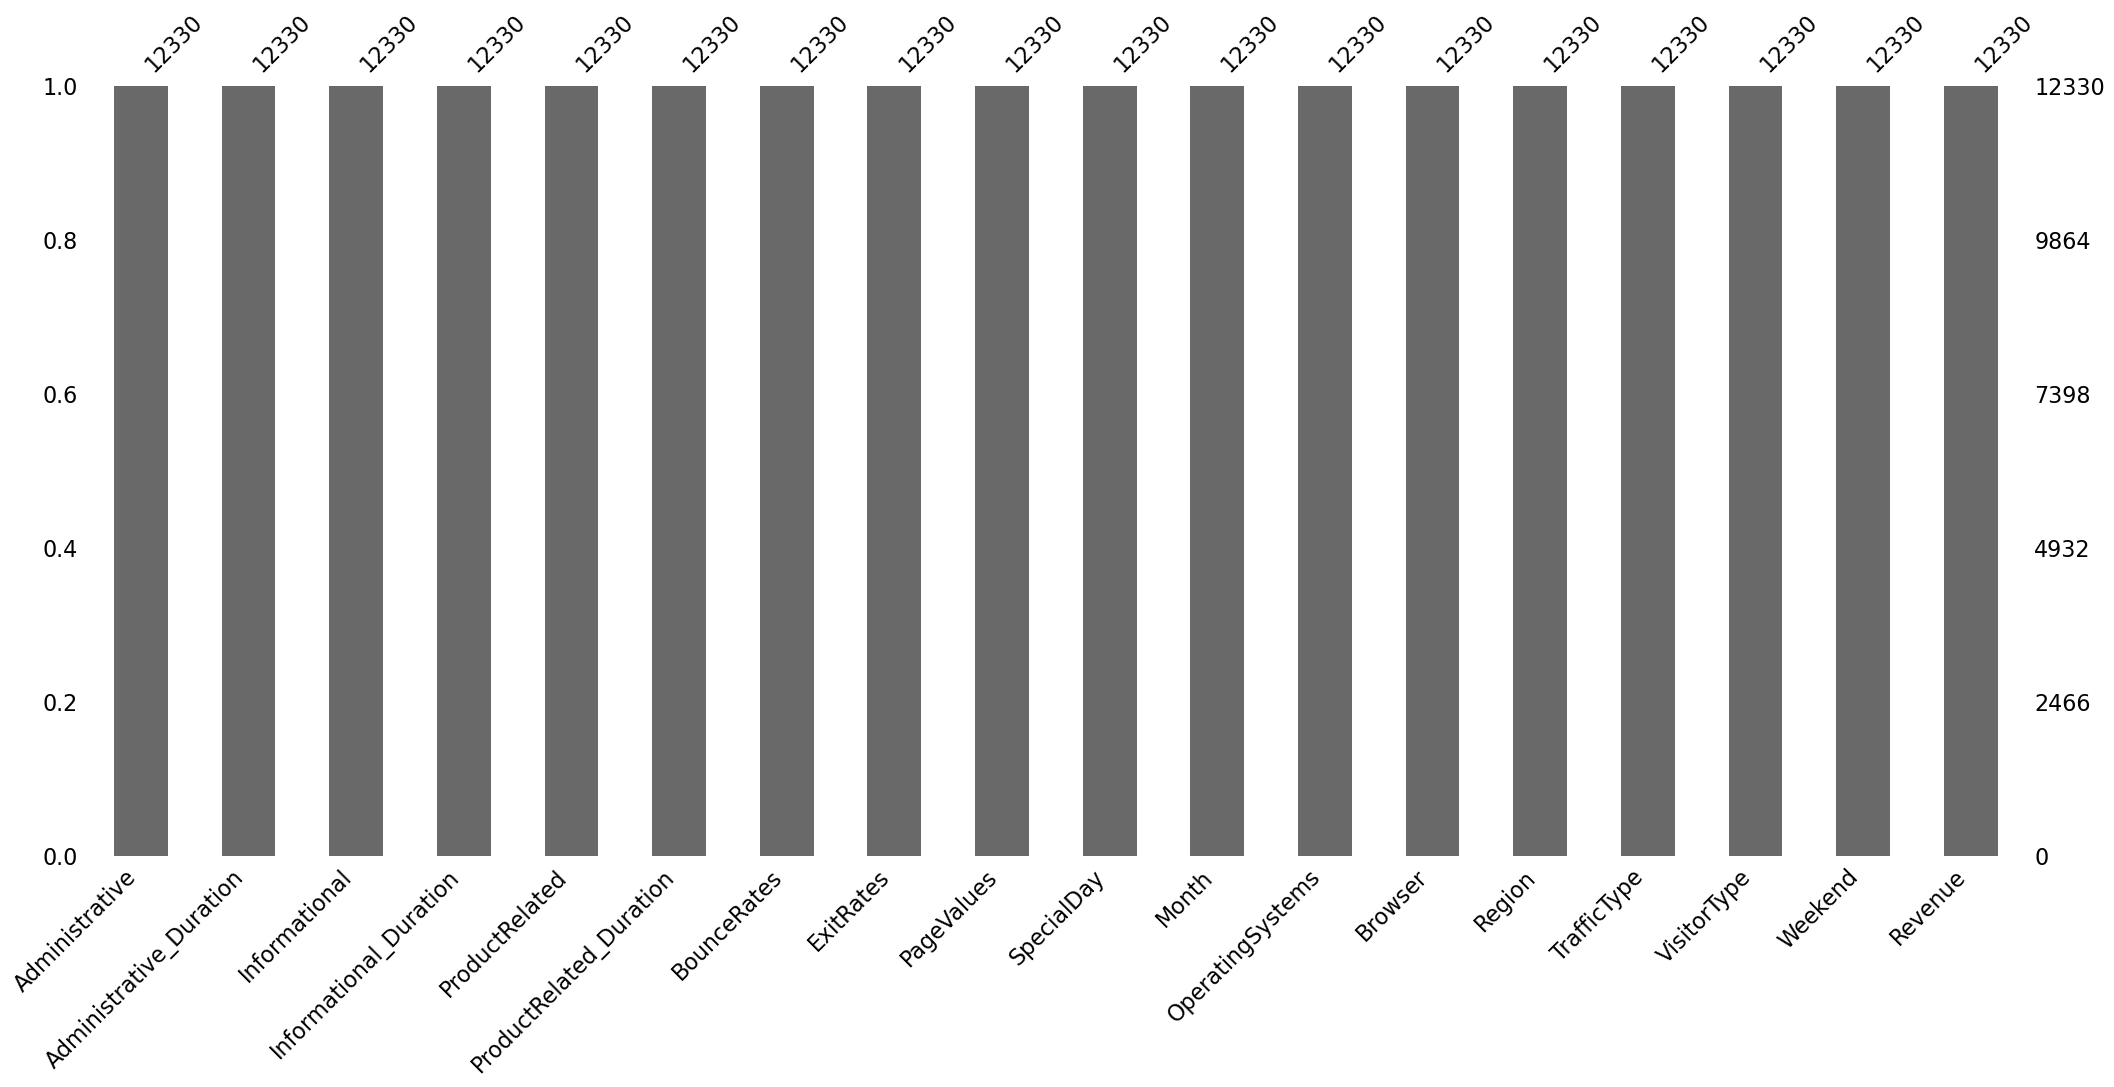

In [8]:
import missingno as msno
msno.bar(df)

### Check Duplicated Data

In [9]:
duplicates = df.duplicated().sum()
display(Markdown(f'**Number of duplicated data:** {duplicates}'))

**Number of duplicated data:** 125

### Check Values of Each Categorical Attribute

In [10]:
#check values of each categorical attribute
cat_attributes = df.select_dtypes(['object']).columns
for i in cat_attributes:
  values = df[i].unique().tolist()
  print(i,': ',values)

Month :  ['Feb', 'Mar', 'May', 'Oct', 'June', 'Jul', 'Aug', 'Nov', 'Sep', 'Dec']
VisitorType :  ['Returning_Visitor', 'New_Visitor', 'Other']


### Exploring Categorical Data

In [11]:
df.select_dtypes(['object']).describe()

,Month,VisitorType
count,12330,12330
unique,10,3
top,May,Returning_Visitor
freq,3364,10551


### Correlation Matrix Heatmap

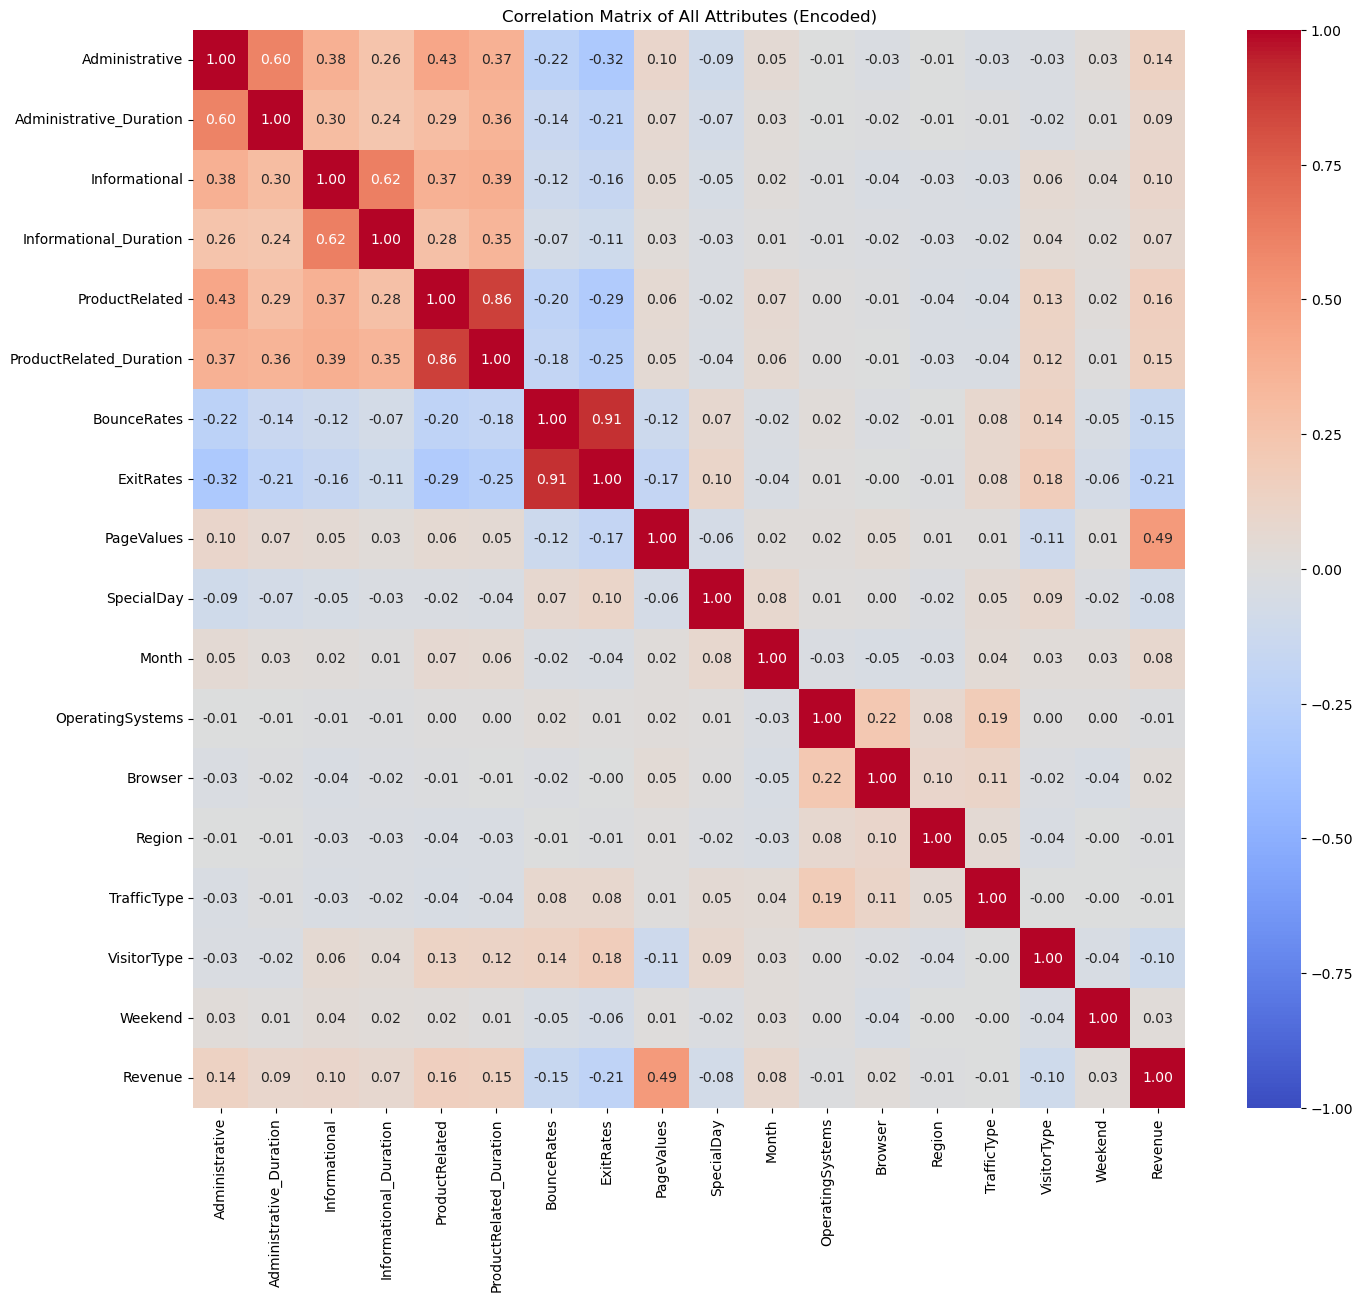

In [12]:
# Create a copy for encoding to avoid modifying the original dataframe used for plots
df_encoded = df.copy()
le = LabelEncoder()

# object columns: Month, VisitorType
# bool columns: Weekend, Revenue
cols_to_encode = df_encoded.select_dtypes(include=['object', 'bool']).columns

for col in cols_to_encode:
    df_encoded[col] = le.fit_transform(df_encoded[col])

# Calculate correlation matrix for the ENTIRE dataset
corr_matrix_all = df_encoded.corr()

# Plot Heatmap
plt.figure(figsize = (16, 14))
# annot=True shows numbers, fmt='.2f' formats to 2 decimal places
sns.heatmap(corr_matrix_all, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix of All Attributes (Encoded)')
plt.show()

### Visualize Numerical Data Distribution and Pairwise Scatter Plots

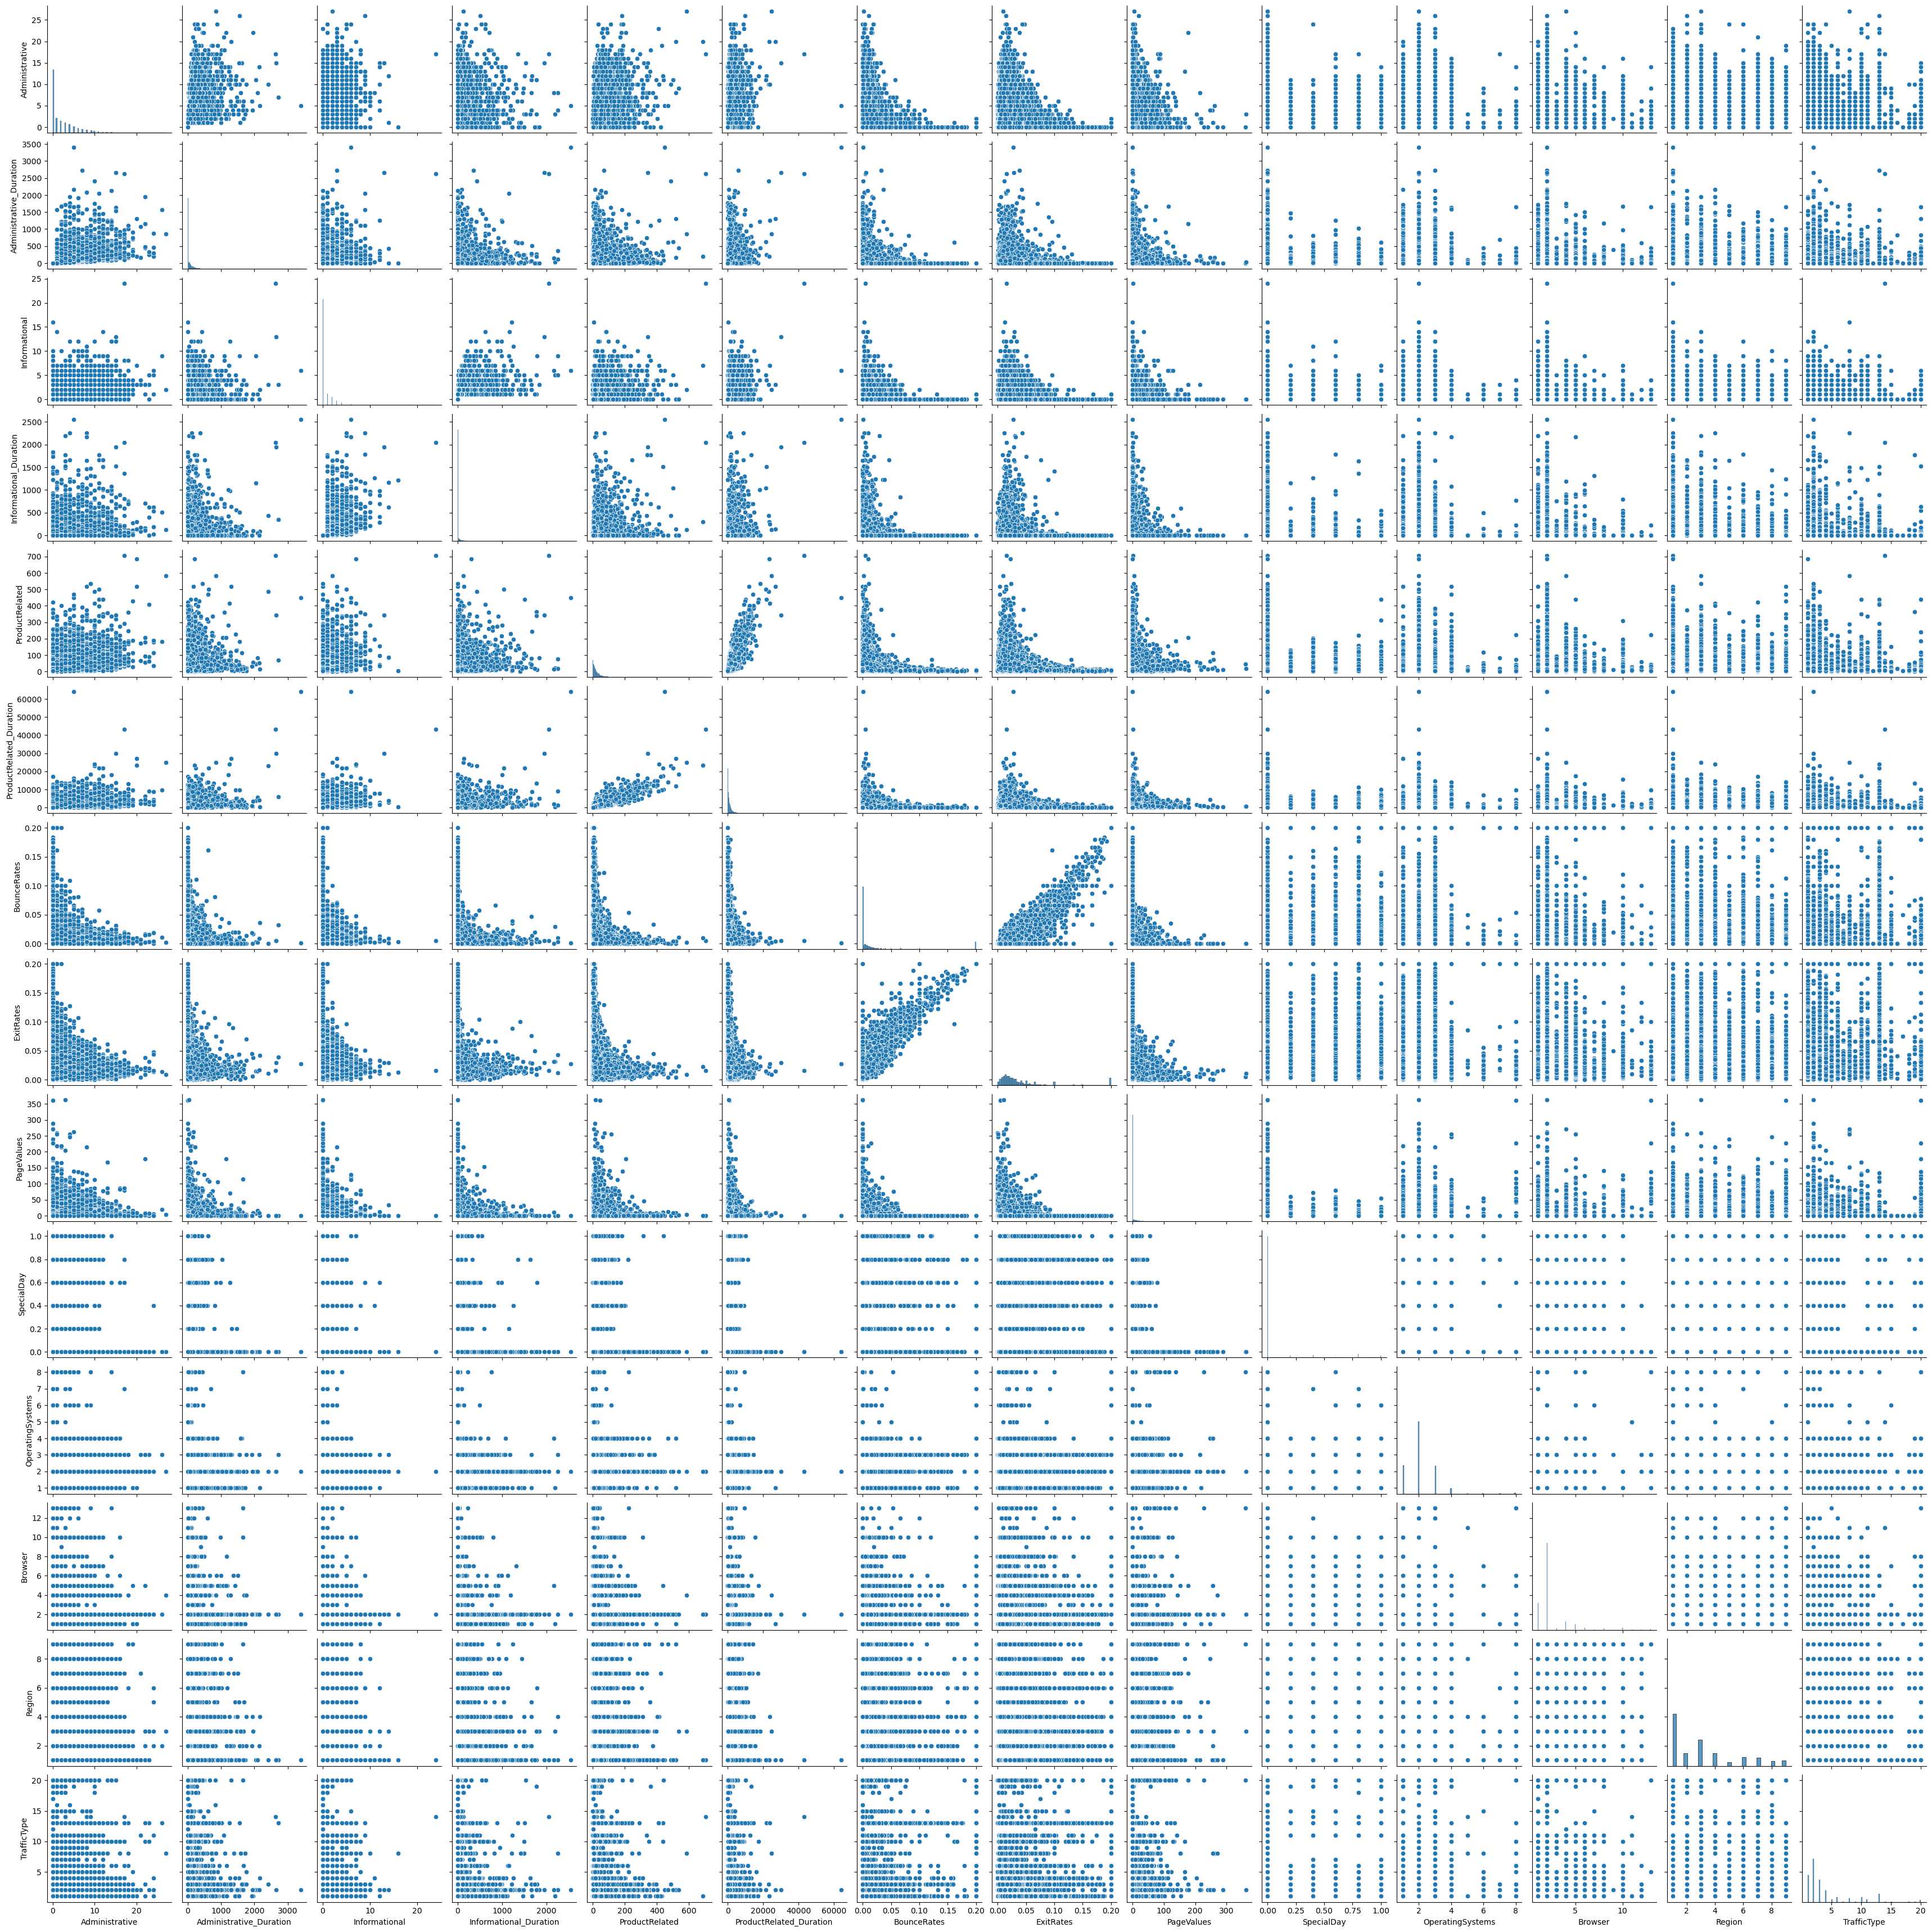

In [13]:
#Visualize numerical data distribution and pairwise scatter plots
#Note: may take time to execute
sns.pairplot(df.select_dtypes(['int64','float64']))

### Distribution of Revenue

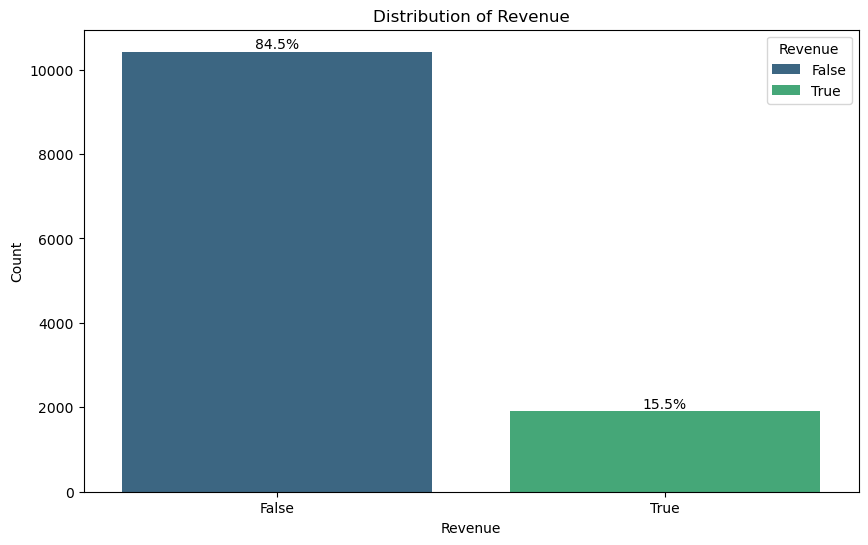

In [14]:
plt.figure(figsize = (10,6))
total = len(df)
b = sns.countplot(x = 'Revenue', data = df, order = df['Revenue'].value_counts().index, hue = 'Revenue', palette = 'viridis')
for container in b.containers:
    labels = [f'{h/total*100:.1f}%' if h > 0 else '' for h in container.datavalues]
    b.bar_label(container, labels=labels)
plt.title('Distribution of Revenue')
plt.xlabel('Revenue')
plt.ylabel('Count')
plt.show()

### Distribution of Month

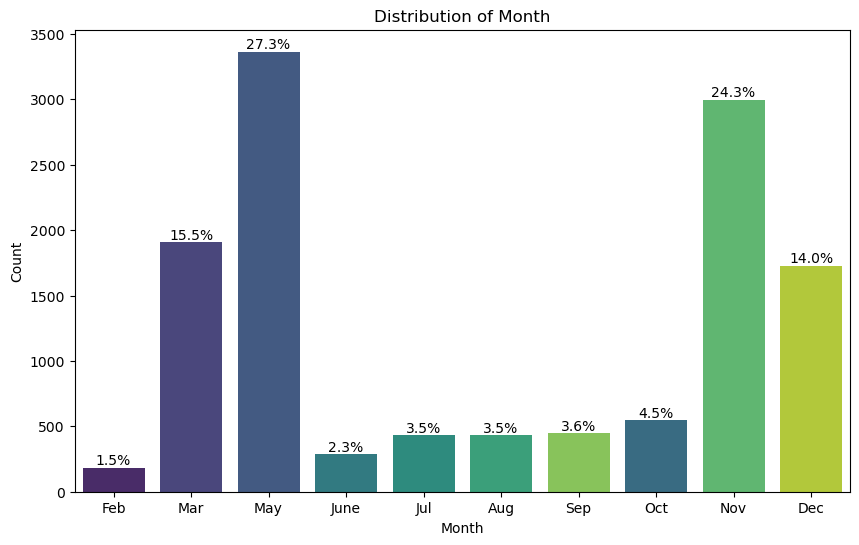

In [15]:
plt.figure(figsize = (10,6))
# Specific order for Month
order_month = ['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
b = sns.countplot(x = 'Month', data = df, order = order_month, hue = 'Month', palette = 'viridis')
for container in b.containers:
    labels = [f'{h/total*100:.1f}%' if h > 0 else '' for h in container.datavalues]
    b.bar_label(container, labels=labels)
plt.title('Distribution of Month')
plt.xlabel('Month')
plt.ylabel('Count')
plt.show()

### Distribution of Visitor Type

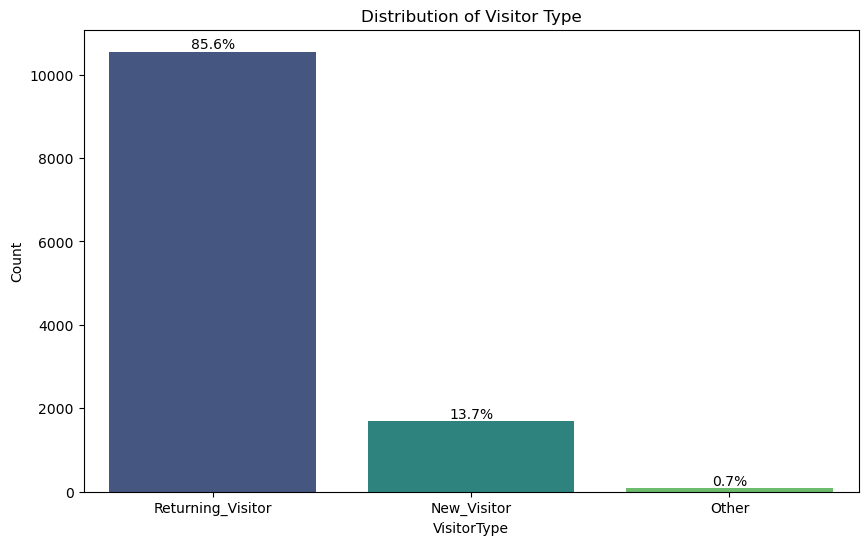

In [16]:
plt.figure(figsize = (10,6))
order_visitor = df['VisitorType'].value_counts().index
b = sns.countplot(x = 'VisitorType', data = df, order = order_visitor, hue = 'VisitorType', palette = 'viridis')
for container in b.containers:
    labels = [f'{h/total*100:.1f}%' if h > 0 else '' for h in container.datavalues]
    b.bar_label(container, labels=labels)
plt.title('Distribution of Visitor Type')
plt.xlabel('VisitorType')
plt.ylabel('Count')
plt.show()

### Distribution of Weekend

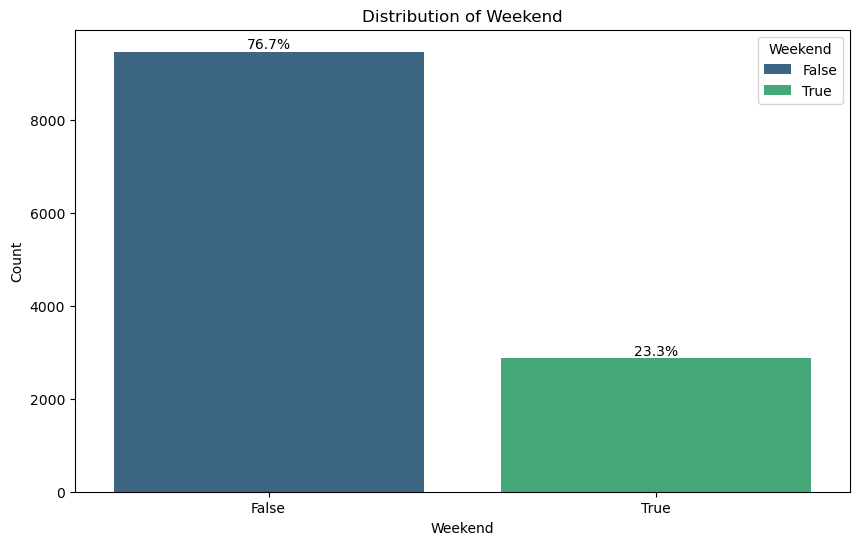

In [17]:
plt.figure(figsize = (10,6))
order_weekend = df['Weekend'].value_counts().index
b = sns.countplot(x = 'Weekend', data = df, order = order_weekend, hue = 'Weekend', palette = 'viridis')
for container in b.containers:
    labels = [f'{h/total*100:.1f}%' if h > 0 else '' for h in container.datavalues]
    b.bar_label(container, labels=labels)
plt.title('Distribution of Weekend')
plt.xlabel('Weekend')
plt.ylabel('Count')
plt.show()

### Distribution of Region

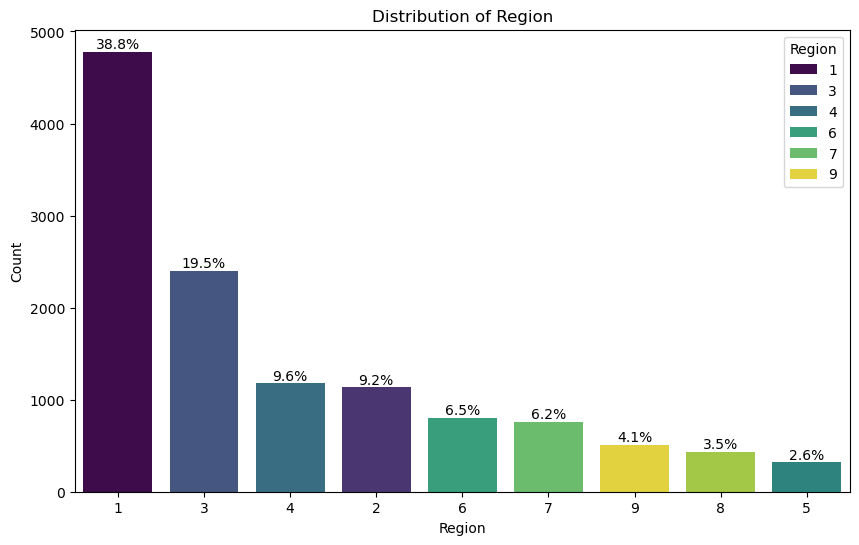

In [18]:
plt.figure(figsize = (10,6))
order_region = df['Region'].value_counts().index
b = sns.countplot(x = 'Region', data = df, order = order_region, hue = 'Region', palette = 'viridis')
for container in b.containers:
    labels = [f'{h/total*100:.1f}%' if h > 0 else '' for h in container.datavalues]
    b.bar_label(container, labels=labels)
plt.title('Distribution of Region')
plt.xlabel('Region')
plt.ylabel('Count')
plt.show()

### Distribution of Browser

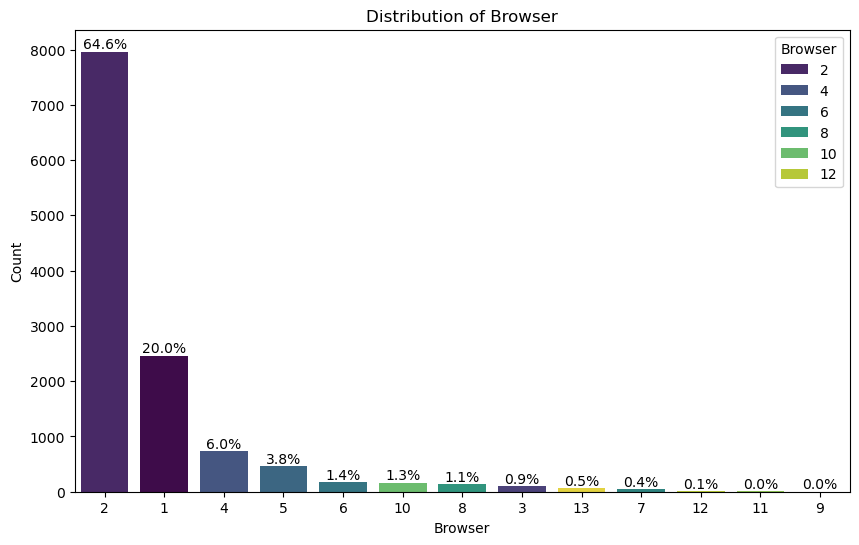

In [19]:
plt.figure(figsize = (10,6))
order_browser = df['Browser'].value_counts().index
b = sns.countplot(x = 'Browser', data = df, order = order_browser, hue = 'Browser', palette = 'viridis')
for container in b.containers:
    labels = [f'{h/total*100:.1f}%' if h > 0 else '' for h in container.datavalues]
    b.bar_label(container, labels=labels)
plt.title('Distribution of Browser')
plt.xlabel('Browser')
plt.ylabel('Count')
plt.show()

### Distribution of Operating System

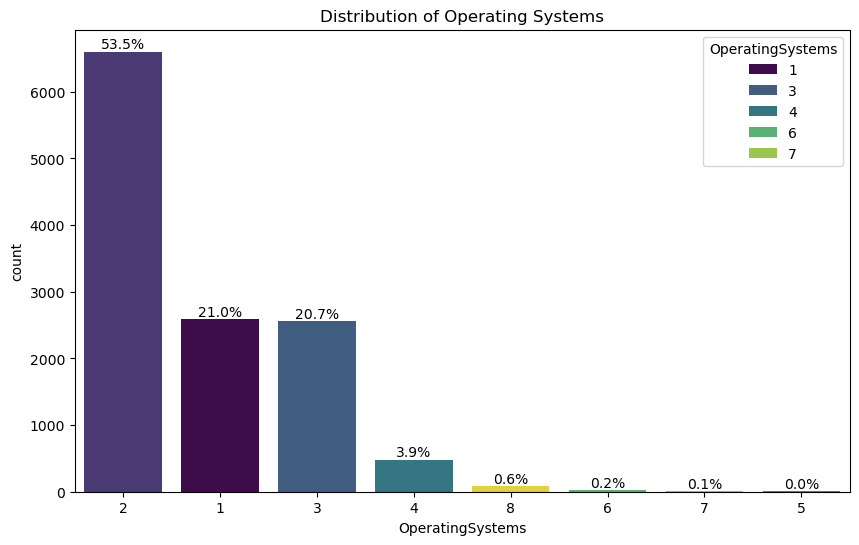

In [20]:
plt.figure(figsize = (10,6))
b = sns.countplot(x = 'OperatingSystems', data = df, order = df['OperatingSystems'].value_counts().index, hue = 'OperatingSystems', palette = 'viridis')
for container in b.containers:
    labels = [f'{h/total*100:.1f}%' if h > 0 else '' for h in container.datavalues]
    b.bar_label(container, labels=labels)
plt.title('Distribution of Operating Systems')
plt.show()

### Distribution of Traffic Type

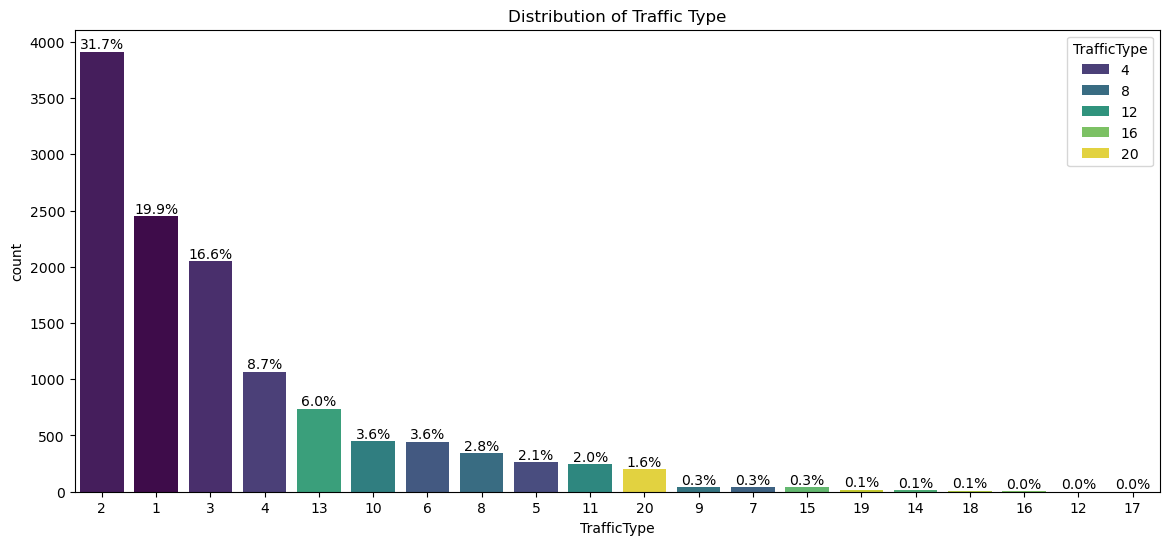

In [21]:
plt.figure(figsize = (14,6))
b = sns.countplot(x = 'TrafficType', data = df, order = df['TrafficType'].value_counts().index, hue = 'TrafficType', palette = 'viridis')
for container in b.containers:
    labels = [f'{h/total*100:.1f}%' if h > 0 else '' for h in container.datavalues]
    b.bar_label(container, labels=labels)
plt.title('Distribution of Traffic Type')
plt.show()

### Distribution of Administrative

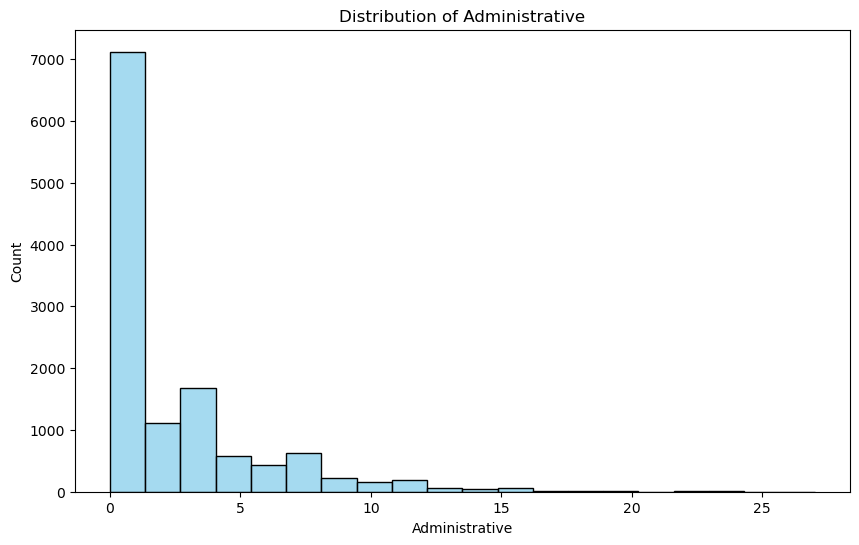

In [22]:
plt.figure(figsize=(10, 6))
sns.histplot(df['Administrative'], kde=False, color='skyblue', bins=20)
plt.title('Distribution of Administrative')
plt.xlabel('Administrative')
plt.show()

### Boxplot of Administrative

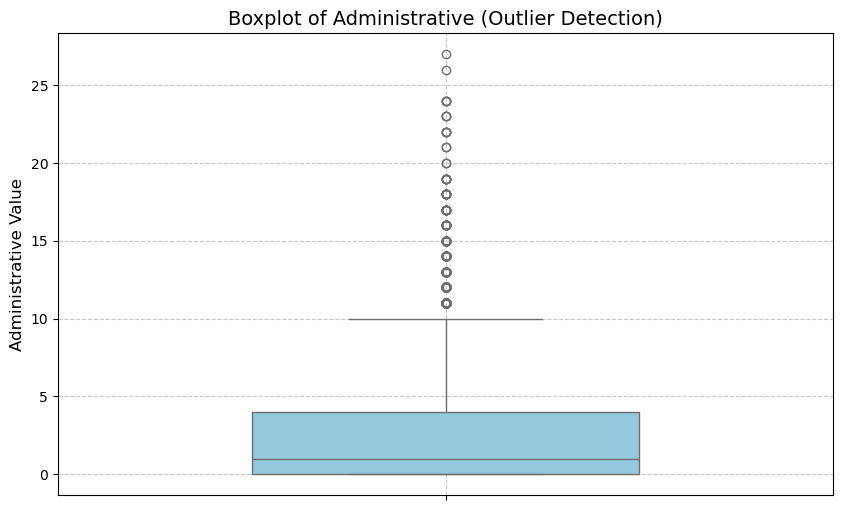

In [23]:
plt.figure(figsize=(10, 6))
sns.boxplot(y=df['Administrative'], color='skyblue', width=0.5)
plt.title('Boxplot of Administrative (Outlier Detection)', fontsize=14)
plt.ylabel('Administrative Value', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Distribution of Administrative Duration

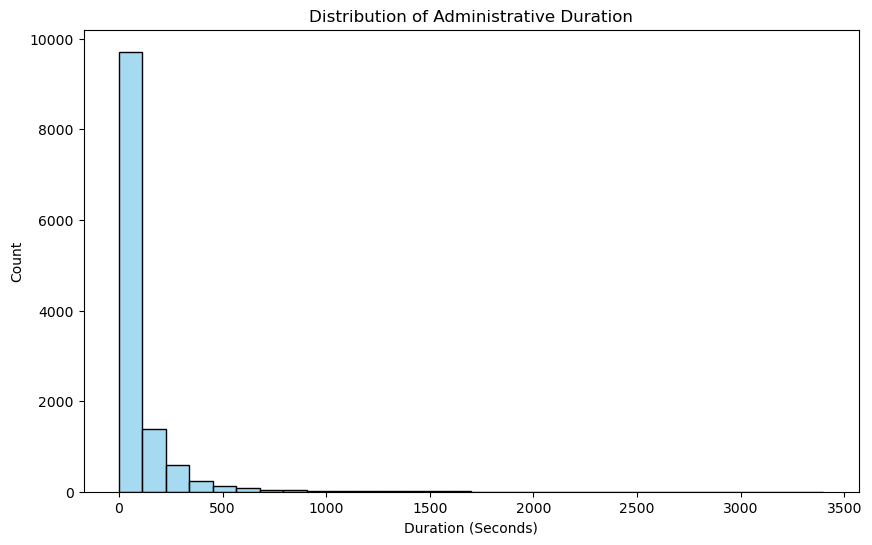

In [24]:
plt.figure(figsize=(10, 6))
sns.histplot(df['Administrative_Duration'], kde=False, color='skyblue', bins=30)
plt.title('Distribution of Administrative Duration')
plt.xlabel('Duration (Seconds)')
plt.show()

### Boxplot of Administrative Duration

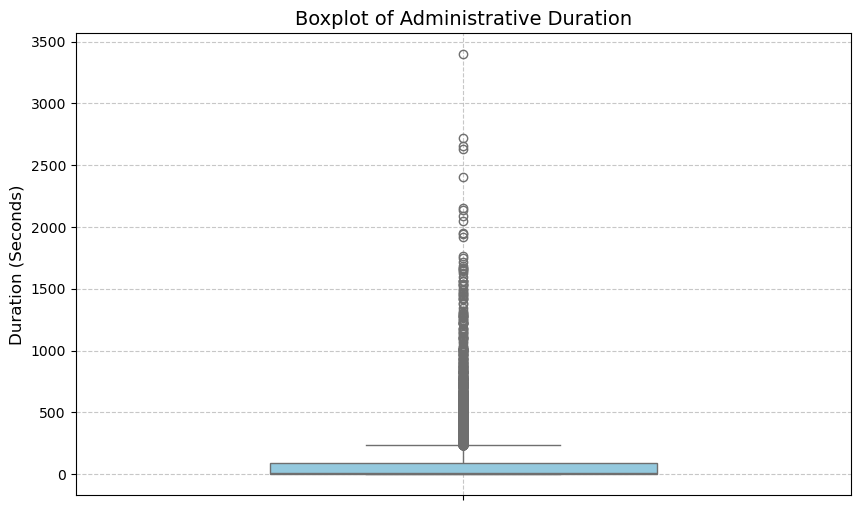

In [25]:
plt.figure(figsize=(10, 6))
sns.boxplot(y=df['Administrative_Duration'], color='skyblue', width=0.5)
plt.title('Boxplot of Administrative Duration', fontsize=14)
plt.ylabel('Duration (Seconds)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Distribution of Informational

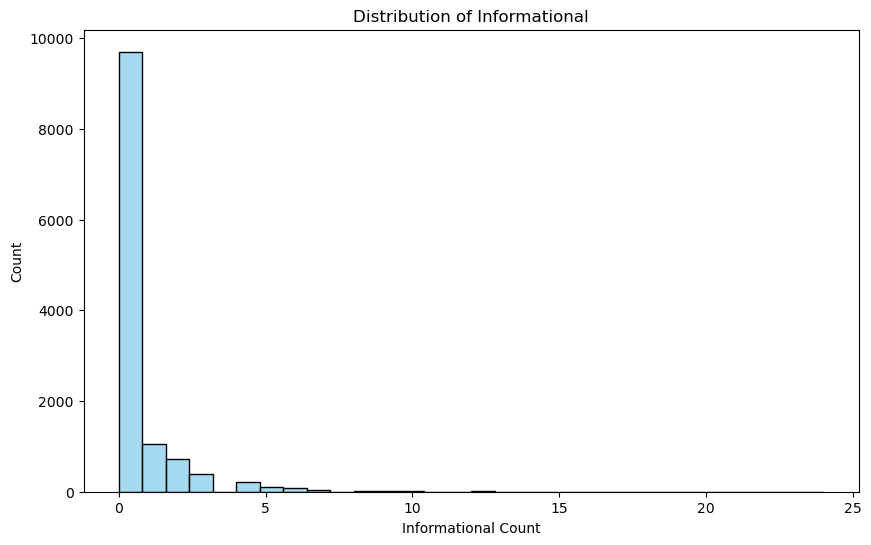

In [26]:
plt.figure(figsize=(10, 6))
sns.histplot(df['Informational'], kde=False, color='skyblue', bins=30)
plt.title('Distribution of Informational')
plt.xlabel('Informational Count')
plt.show()

### Boxplot of Informational

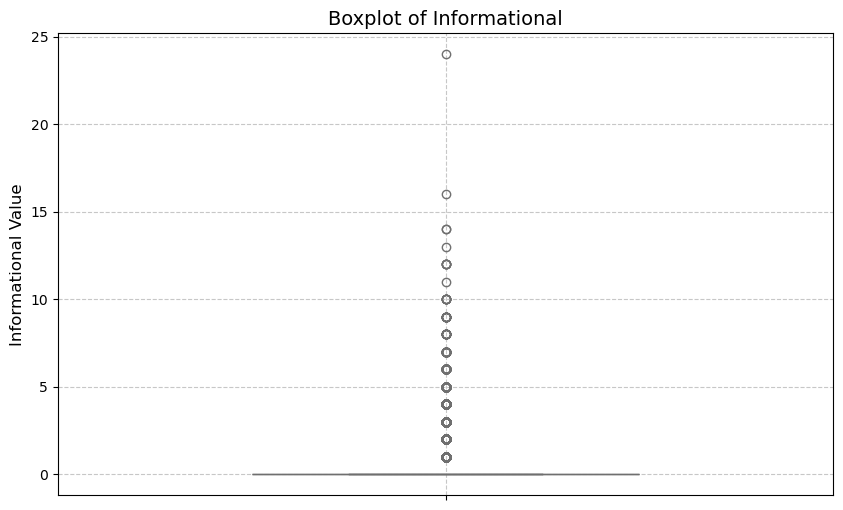

In [27]:
plt.figure(figsize=(10, 6))
sns.boxplot(y=df['Informational'], color='skyblue', width=0.5)
plt.title('Boxplot of Informational', fontsize=14)
plt.ylabel('Informational Value', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Distribution of Informational Duration

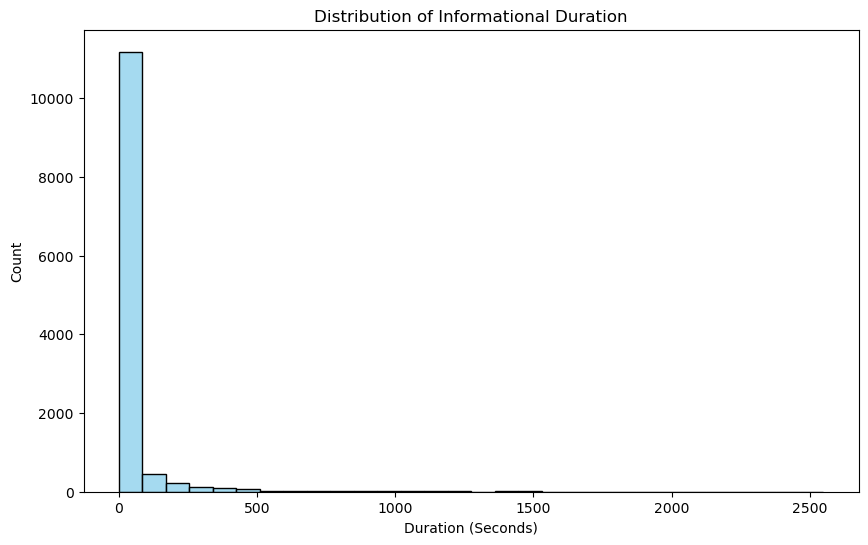

In [28]:
plt.figure(figsize=(10, 6))
sns.histplot(df['Informational_Duration'], kde=False, color='skyblue', bins=30)
plt.title('Distribution of Informational Duration')
plt.xlabel('Duration (Seconds)')
plt.show()

### Boxplot of Informational Duration

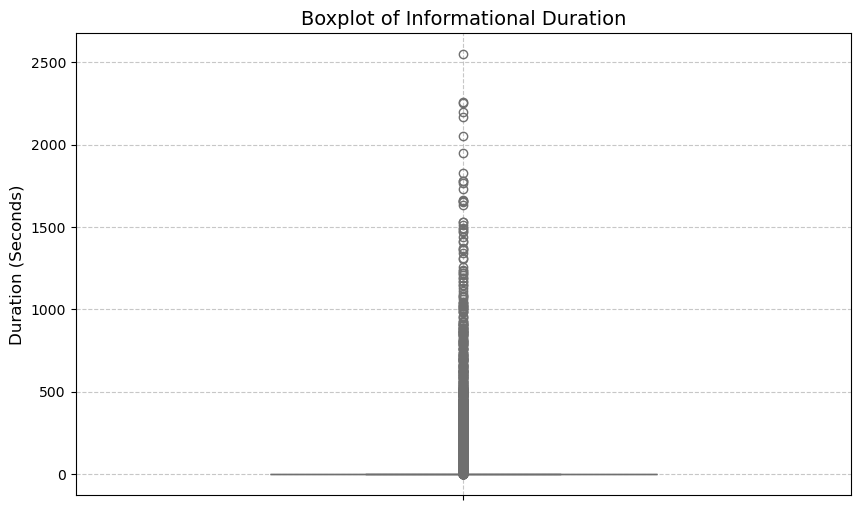

In [29]:
plt.figure(figsize=(10, 6))
sns.boxplot(y=df['Informational_Duration'], color='skyblue', width=0.5)
plt.title('Boxplot of Informational Duration', fontsize=14)
plt.ylabel('Duration (Seconds)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Distribution of ProductRelated

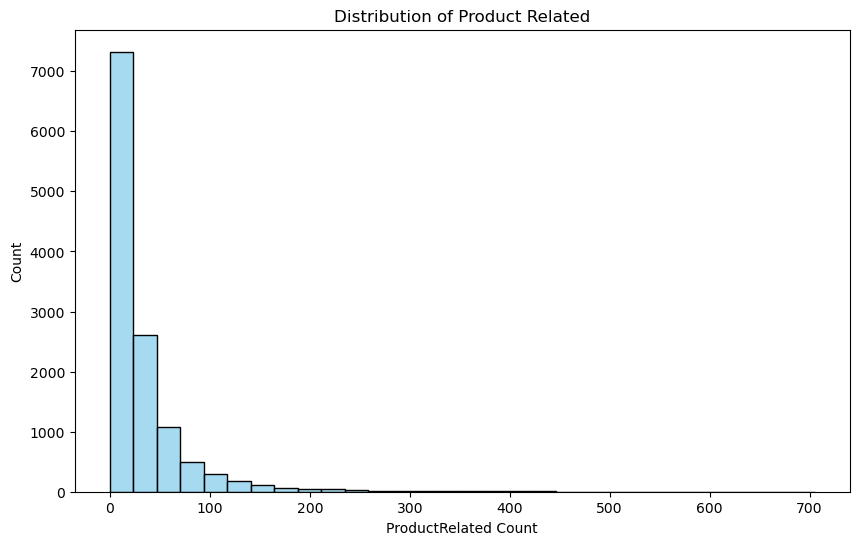

In [30]:
plt.figure(figsize=(10, 6))
sns.histplot(df['ProductRelated'], kde=False, color='skyblue', bins=30)
plt.title('Distribution of Product Related')
plt.xlabel('ProductRelated Count')
plt.show()

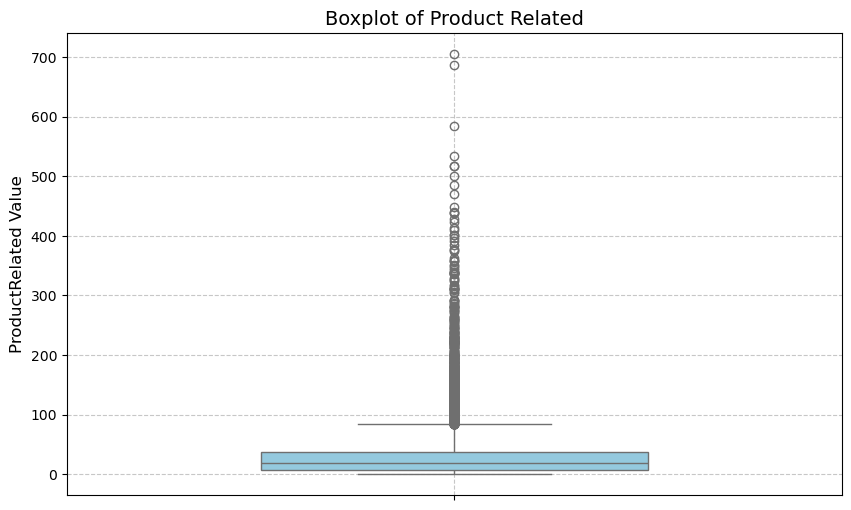

In [31]:
plt.figure(figsize=(10, 6))
sns.boxplot(y=df['ProductRelated'], color='skyblue', width=0.5)
plt.title('Boxplot of Product Related', fontsize=14)
plt.ylabel('ProductRelated Value', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Distribution of ProductRelated Duration

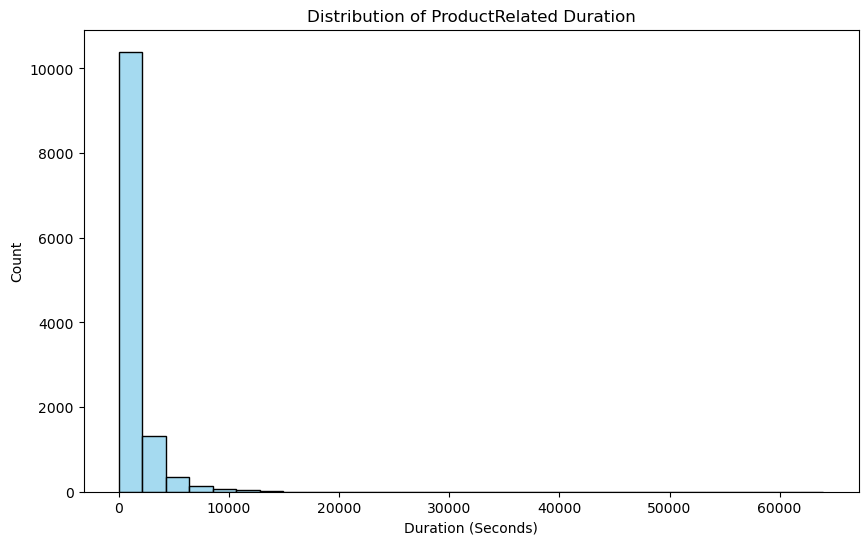

In [32]:
plt.figure(figsize=(10, 6))
sns.histplot(df['ProductRelated_Duration'], kde=False, color='skyblue', bins=30)
plt.title('Distribution of ProductRelated Duration')
plt.xlabel('Duration (Seconds)')
plt.show()

### Boxplot of ProductRelated Duration

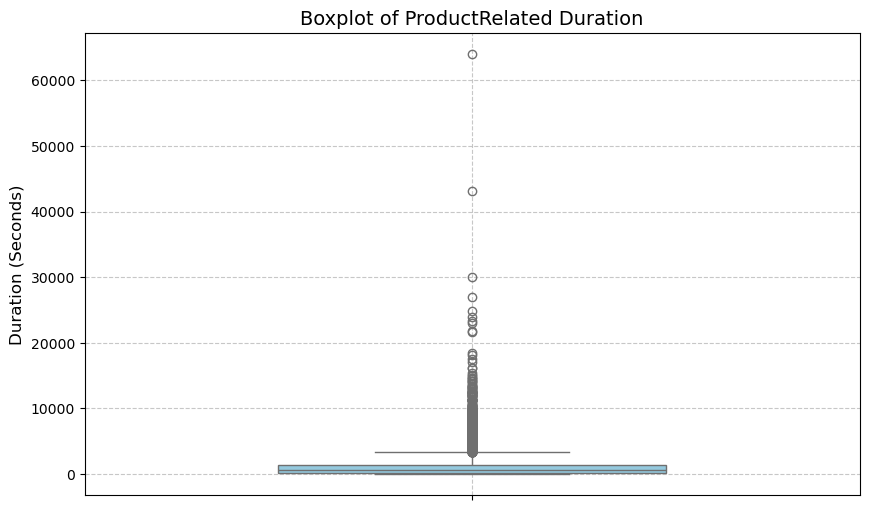

In [33]:
plt.figure(figsize=(10, 6))
sns.boxplot(y=df['ProductRelated_Duration'], color='skyblue', width=0.5)
plt.title('Boxplot of ProductRelated Duration', fontsize=14)
plt.ylabel('Duration (Seconds)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Distribution of Bounce Rates

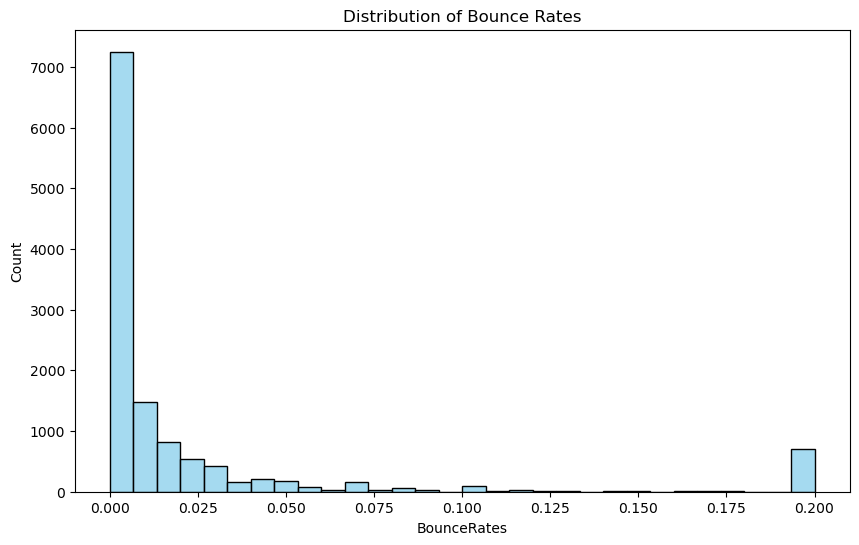

In [34]:
plt.figure(figsize=(10, 6))
sns.histplot(df['BounceRates'], kde=False, color='skyblue', bins=30)
plt.title('Distribution of Bounce Rates')
plt.xlabel('BounceRates')
plt.show()

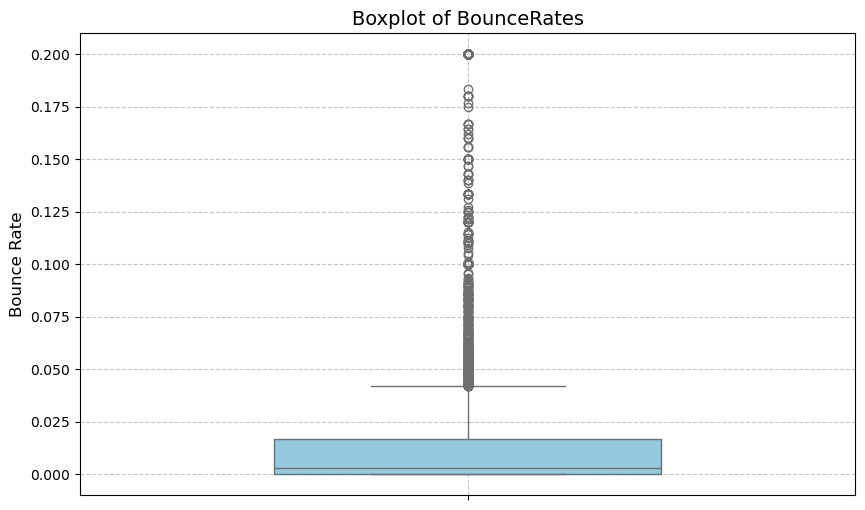

In [35]:
plt.figure(figsize=(10, 6))
sns.boxplot(y=df['BounceRates'], color='skyblue', width=0.5)
plt.title('Boxplot of BounceRates', fontsize=14)
plt.ylabel('Bounce Rate', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Distribution of Exit Rates

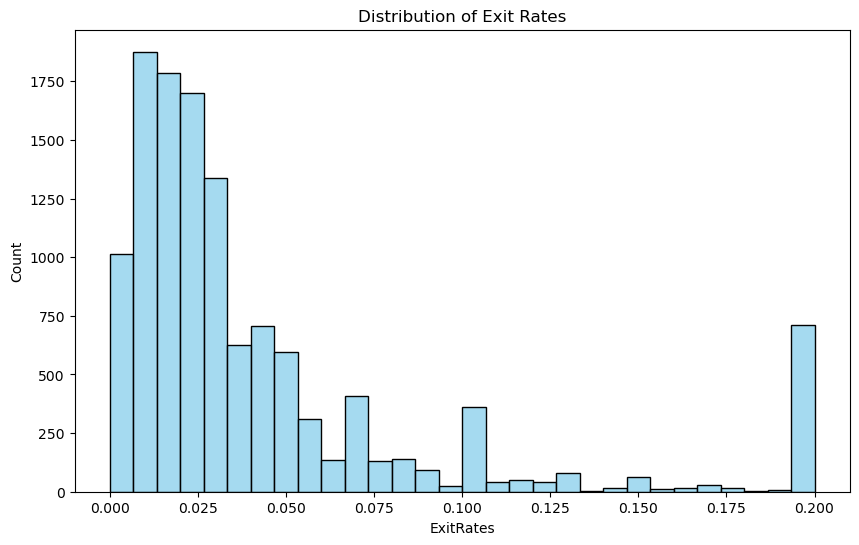

In [36]:
plt.figure(figsize=(10, 6))
sns.histplot(df['ExitRates'], kde=False, color='skyblue', bins=30)
plt.title('Distribution of Exit Rates')
plt.xlabel('ExitRates')
plt.show()

### Boxplot of Exit Rates

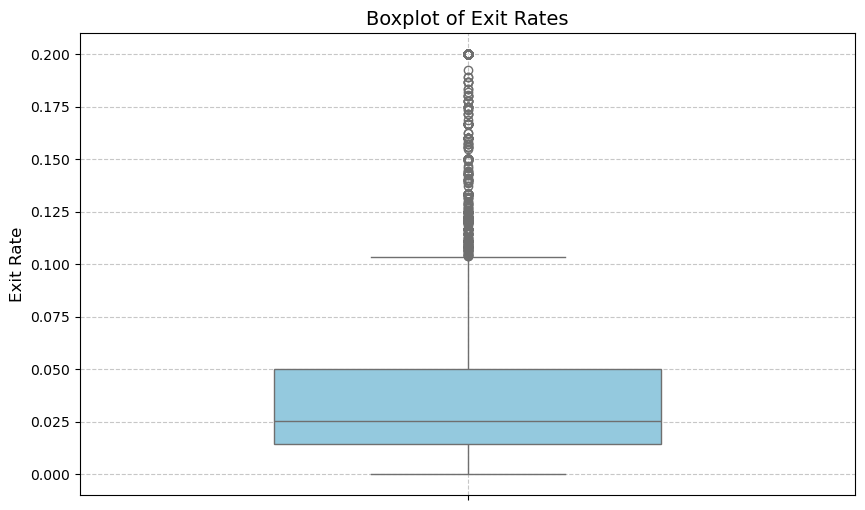

In [37]:
plt.figure(figsize=(10, 6))
sns.boxplot(y=df['ExitRates'], color='skyblue', width=0.5)
plt.title('Boxplot of Exit Rates', fontsize=14)
plt.ylabel('Exit Rate', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Distribution of Page Values

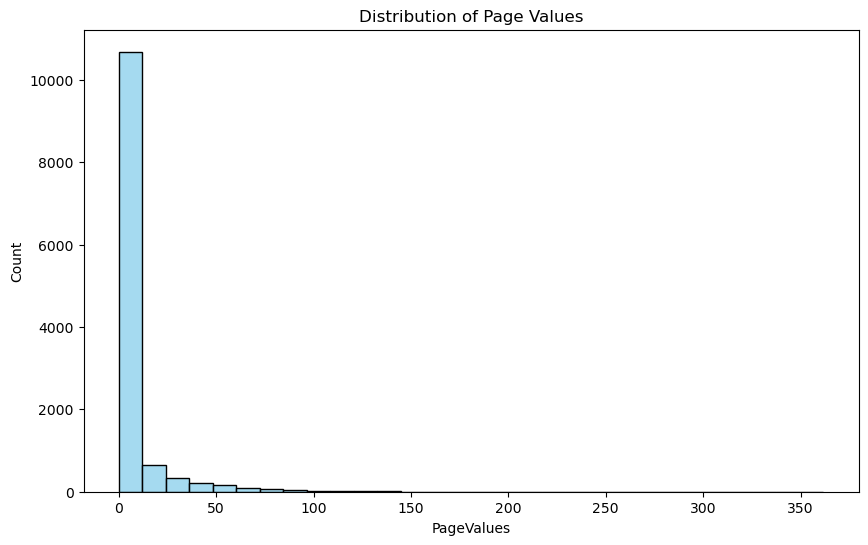

In [38]:
plt.figure(figsize=(10, 6))
sns.histplot(df['PageValues'], kde=False, color='skyblue', bins=30)
plt.title('Distribution of Page Values')
plt.xlabel('PageValues')
plt.show()

### Boxplot of Page Values

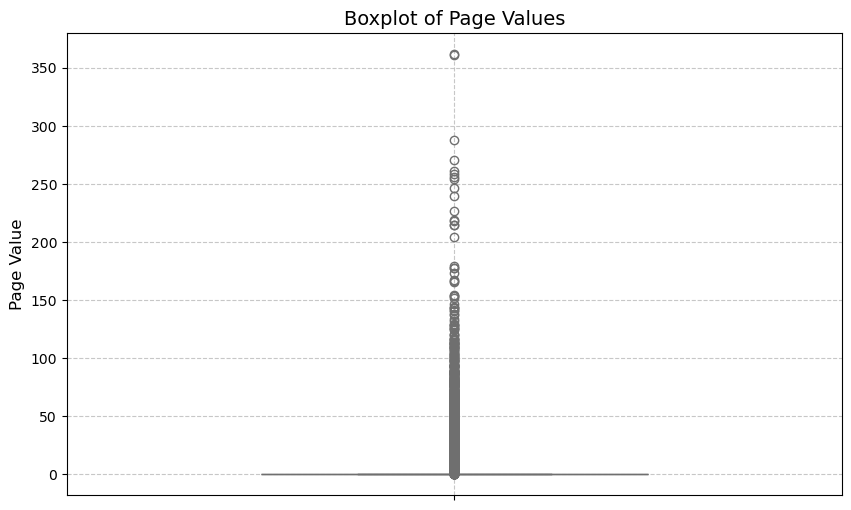

In [39]:
plt.figure(figsize=(10, 6))
sns.boxplot(y=df['PageValues'], color='skyblue', width=0.5)
plt.title('Boxplot of Page Values', fontsize=14)
plt.ylabel('Page Value', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Distribution of Special Day

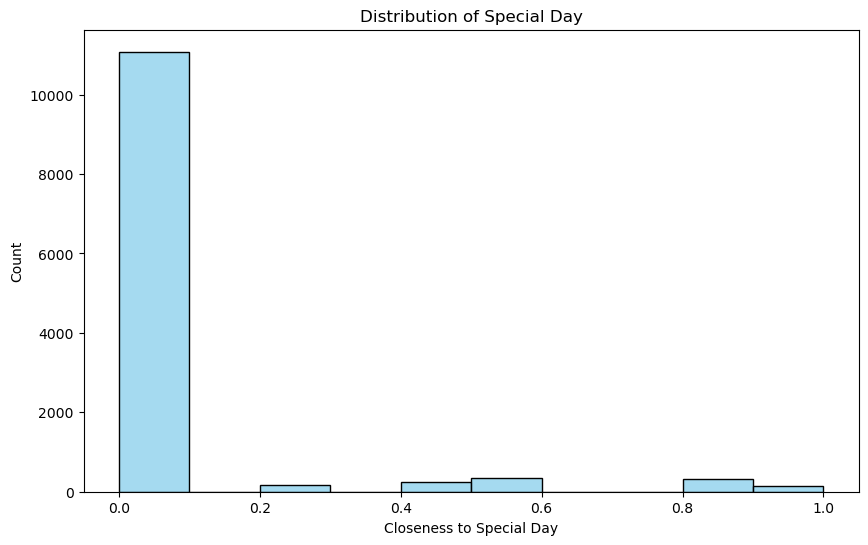

In [40]:
plt.figure(figsize=(10, 6))
sns.histplot(df['SpecialDay'], kde=False, color='skyblue', bins=10)
plt.title('Distribution of Special Day')
plt.xlabel('Closeness to Special Day')
plt.show()

### Boxplot of Special Day

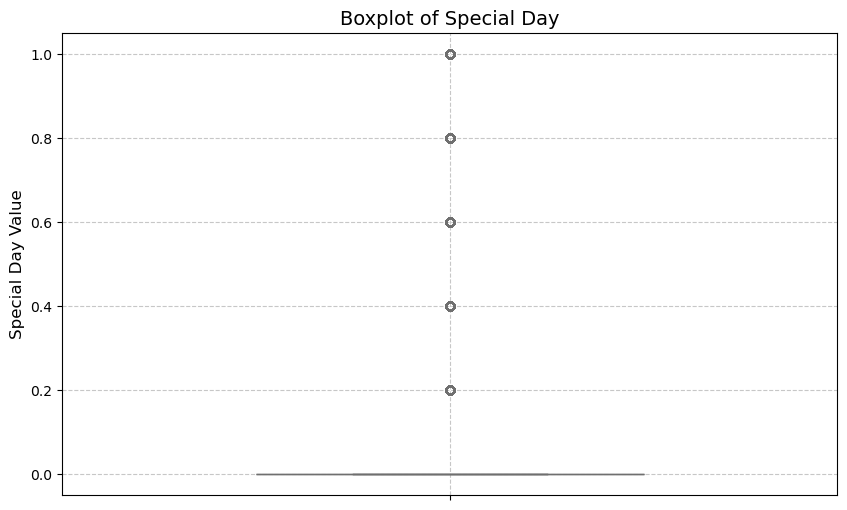

In [41]:
plt.figure(figsize=(10, 6))
sns.boxplot(y=df['SpecialDay'], color='skyblue', width=0.5)
plt.title('Boxplot of Special Day', fontsize=14)
plt.ylabel('Special Day Value', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Page Values by Revenue

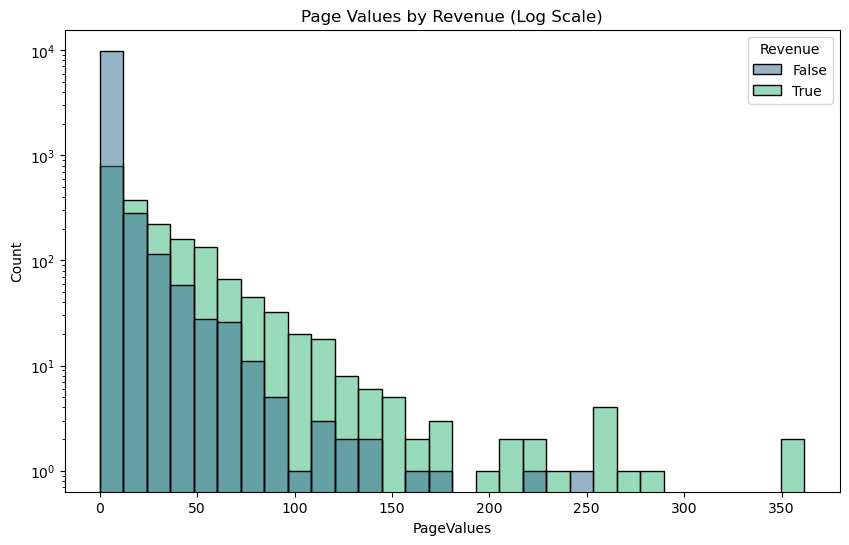

In [42]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='PageValues', hue='Revenue', bins=30, kde=False, palette='viridis')
plt.yscale('log')
plt.title('Page Values by Revenue (Log Scale)')
plt.show()

### Exit Rates by Revenue

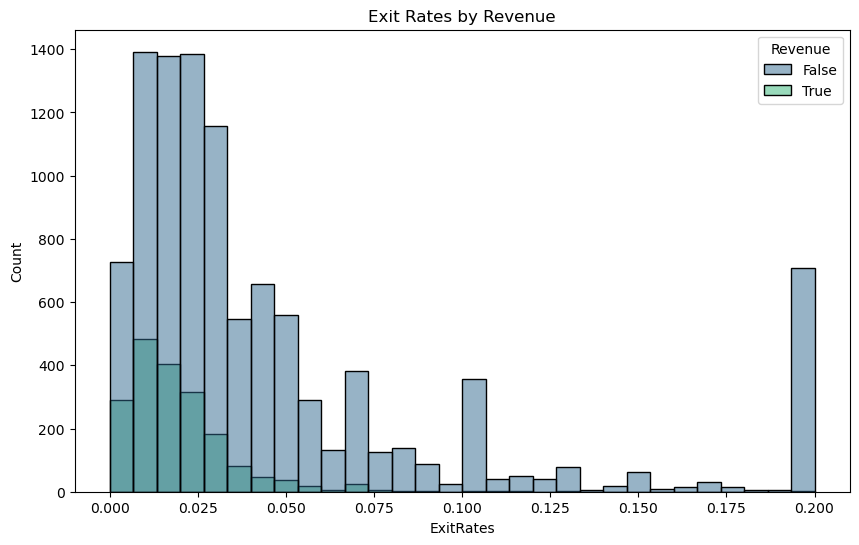

In [43]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='ExitRates', hue='Revenue', bins=30, kde=False, palette='viridis')
plt.title('Exit Rates by Revenue')
plt.show()

### Product Related by Revenue

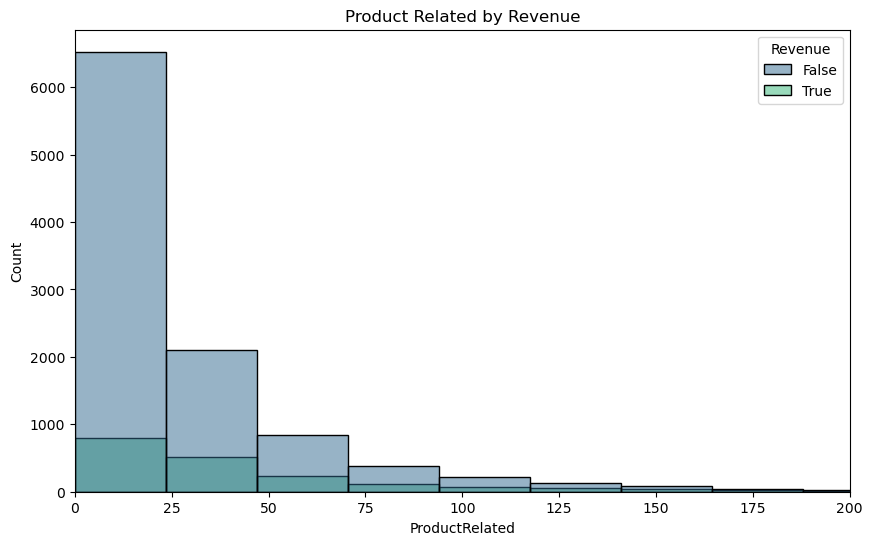

In [44]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='ProductRelated', hue='Revenue', bins=30, kde=False, palette='viridis')
plt.xlim(0, 200)
plt.title('Product Related by Revenue')
plt.show()

### Count of Revenue by Month

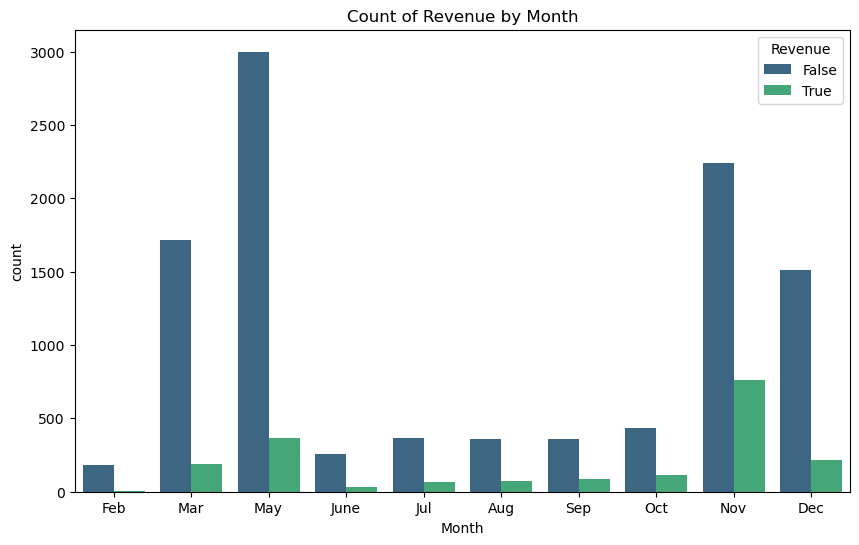

In [45]:
plt.figure(figsize=(10, 6))
order_month = ['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
existing_months = [m for m in order_month if m in df['Month'].unique()]
sns.countplot(x='Month', hue='Revenue', data=df, order=existing_months, palette='viridis')
plt.title('Count of Revenue by Month')
plt.show()

## 2.Data Preprocessing

### Import Library

In [46]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from imblearn.over_sampling import SMOTENC

#random seed
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

### Data Cleaning

In [47]:
initial_rows = df.shape[0]
df = df.drop_duplicates()
display(Markdown(f'**Number of duplicated row remove:** {initial_rows - df.shape[0]}'))
display(Markdown(f'**Current dataset shape:** {df.shape}'))

**Number of duplicated row remove:** 125

**Current dataset shape:** (12205, 18)

In [48]:
df.drop(columns=['BounceRates'], inplace=True)

### Data Transformation

#### Boolean to Binary Conversion

In [49]:
df['Weekend'] = df['Weekend'].astype(int)
df['Revenue'] = df['Revenue'].astype(int)

#### Categorical Encoding

In [50]:
df['Returning_Visitor'] = df['VisitorType'].apply(lambda x: 1 if x == 'Returning_Visitor' else 0)

# Month: "ordinally encoded... integer values from 0 to 11"
month_mapping = {
    'Jan': 0, 'Feb': 1, 'Mar': 2, 'Apr': 3, 'May': 4, 'June': 5,
    'Jul': 6, 'Aug': 7, 'Sep': 8, 'Oct': 9, 'Nov': 10, 'Dec': 11
}
df['Month'] = df['Month'].map(month_mapping).fillna(0)

# delete the attribute visitor type
df_clean = df.drop(columns=['VisitorType'])

### Clean Dataset

In [51]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12205 entries, 0 to 12329
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12205 non-null  int64  
 1   Administrative_Duration  12205 non-null  float64
 2   Informational            12205 non-null  int64  
 3   Informational_Duration   12205 non-null  float64
 4   ProductRelated           12205 non-null  int64  
 5   ProductRelated_Duration  12205 non-null  float64
 6   ExitRates                12205 non-null  float64
 7   PageValues               12205 non-null  float64
 8   SpecialDay               12205 non-null  float64
 9   Month                    12205 non-null  int64  
 10  OperatingSystems         12205 non-null  int64  
 11  Browser                  12205 non-null  int64  
 12  Region                   12205 non-null  int64  
 13  TrafficType              12205 non-null  int64  
 14  Weekend                  12

In [52]:
# --- Display Selected Feature Values ---
display(Markdown('**Feature Values Preview (Head):**'))
display(df_clean.head().T)
display(Markdown('**Feature Values Statistics:**'))
display(df_clean.describe(include = 'all').T)

**Feature Values Preview (Head):**

,0,1,2,3,4
Administrative,0.0,0.0,0.0,0.000000,0.00
Administrative_Duration,0.0,0.0,0.0,0.000000,0.00
Informational,0.0,0.0,0.0,0.000000,0.00
Informational_Duration,0.0,0.0,0.0,0.000000,0.00
ProductRelated,1.0,2.0,1.0,2.000000,10.00
ProductRelated_Duration,0.0,64.0,0.0,2.666667,627.50
ExitRates,0.2,0.1,0.2,0.140000,0.05
PageValues,0.0,0.0,0.0,0.000000,0.00
SpecialDay,0.0,0.0,0.0,0.000000,0.00
Month,1.0,1.0,1.0,1.000000,1.00


**Feature Values Statistics:**

,count,mean,std,min,25%,50%,75%,max
Administrative,12205.0,2.338878,3.330436,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12205.0,81.646331,177.491845,0.0,0.000000,9.000000,94.700000,3398.750000
Informational,12205.0,0.508726,1.275617,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12205.0,34.825454,141.424807,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12205.0,32.045637,44.593649,0.0,8.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12205.0,1206.982457,1919.601400,0.0,193.000000,608.942857,1477.154762,63973.522230
ExitRates,12205.0,0.041466,0.046163,0.0,0.014231,0.025000,0.048529,0.200000
PageValues,12205.0,5.949574,18.653671,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12205.0,0.061942,0.199666,0.0,0.000000,0.000000,0.000000,1.000000
Month,12205.0,6.667431,3.386705,1.0,4.000000,7.000000,10.000000,11.000000


### Splitting Data

#### Remove Target Variable

In [53]:
X = df_clean.drop(columns=['Revenue'])
y = df_clean['Revenue']

#### Train Test Split

In [54]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)

display(Markdown(f'**Training Set:** {X_train.shape}'))
display(Markdown(f'**Testing Set:** {X_test.shape}'))

**Training Set:** (8543, 16)

**Testing Set:** (3662, 16)

### Apply Min Max Scaling

In [55]:
scaler = MinMaxScaler()

X_train_scaled_array = scaler.fit_transform(X_train)
X_test_scaled_array = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(X_train_scaled_array, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled_array, columns=X_test.columns)

### Class Balancing (SMOTENC)

In [56]:
# Define categorical features (LabelEncoded ones & boolean converted)
categorical_cols = ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'Weekend', 'Returning_Visitor']

# Get indices of these columns in the X_train dataset
if isinstance(X_train, pd.DataFrame):
    cat_indices = [X_train.columns.get_loc(c) for c in categorical_cols if c in X_train.columns]
else:
    cat_indices = [X.columns.get_loc(c) for c in categorical_cols if c in X.columns]

print(f"Categorical Feature Indices for SMOTENC: {cat_indices}")

# Apply SMOTENC
smote_nc = SMOTENC(categorical_features=cat_indices, random_state=RANDOM_STATE)
X_train_balanced, y_train_balanced = smote_nc.fit_resample(X_train_scaled, y_train)

print("Original class distribution:", y_train.value_counts().to_dict())
print("Balanced class distribution:", y_train_balanced.value_counts().to_dict())

Categorical Feature Indices for SMOTENC: [9, 10, 11, 12, 13, 14, 15]
Original class distribution: {0: 7207, 1: 1336}
Balanced class distribution: {0: 7207, 1: 7207}


### Feature Selection

In [57]:
# 1. Reconstruct DataFrame from balanced data (for column names)
X_train_balanced_df = pd.DataFrame(X_train_balanced, columns=X_train.columns)

# 2. DROP Features (Anonymized/Unwanted)
drop_features = ['Administrative','Administrative_Duration','Informational','Informational_Duration','OperatingSystems', 'Browser', 'Region', 'TrafficType']
X_train_f_classif = X_train_balanced_df.drop(columns=drop_features, errors='ignore')

selector = SelectKBest(score_func=f_classif, k=7)

# 4. Fit Selector
selector.fit(X_train_f_classif, y_train_balanced)

# 5. Get Selected Features
selected_cols = X_train_f_classif.columns[selector.get_support()].tolist()
display(Markdown(f'**ANOVA F-Test Selected Features:** {selected_cols}'))

# 6. Transform Data
X_train_final = X_train_balanced_df[selected_cols]
# Map feature names to indices for safe array slicing on test set
feature_indices = [X_train.columns.get_loc(c) for c in selected_cols]
X_test_final = X_test_scaled.iloc[:, feature_indices]

**ANOVA F-Test Selected Features:** ['ProductRelated', 'ProductRelated_Duration', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'Returning_Visitor']

In [58]:
# --- Display Selected Feature Values ---
display(Markdown('**Feature Values Preview (Head):**'))
display(X_train_final.head())
display(Markdown('**Feature Values Statistics:**'))
display(X_train_final.describe())

**Feature Values Preview (Head):**

,ProductRelated,ProductRelated_Duration,ExitRates,PageValues,SpecialDay,Month,Returning_Visitor
0,0.024781,0.006477,0.026316,0.0,0.0,0.3,1.0
1,0.016035,0.016499,0.212121,0.0,0.0,0.3,1.0
2,0.011662,0.009488,0.312500,0.0,0.0,0.1,1.0
3,0.013120,0.002407,0.153846,0.0,0.0,0.3,1.0
4,0.034985,0.014295,0.083333,0.0,0.4,0.3,1.0


**Feature Values Statistics:**

,ProductRelated,ProductRelated_Duration,ExitRates,PageValues,SpecialDay,Month,Returning_Visitor
count,14414.000000,14414.000000,14414.000000,14414.000000,14414.000000,14414.000000,14414.000000
mean,0.056327,0.022902,0.161122,0.040385,0.045141,0.616033,0.837172
std,0.072296,0.030823,0.191225,0.079721,0.171279,0.335475,0.369221
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.016035,0.005350,0.059829,0.000000,0.000000,0.300000,1.000000
50%,0.033528,0.013222,0.100276,0.000000,0.000000,0.800000,1.000000
75%,0.067055,0.028097,0.174302,0.049865,0.000000,0.900000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


### Pearson Correlation Coefficient (with Revenue)

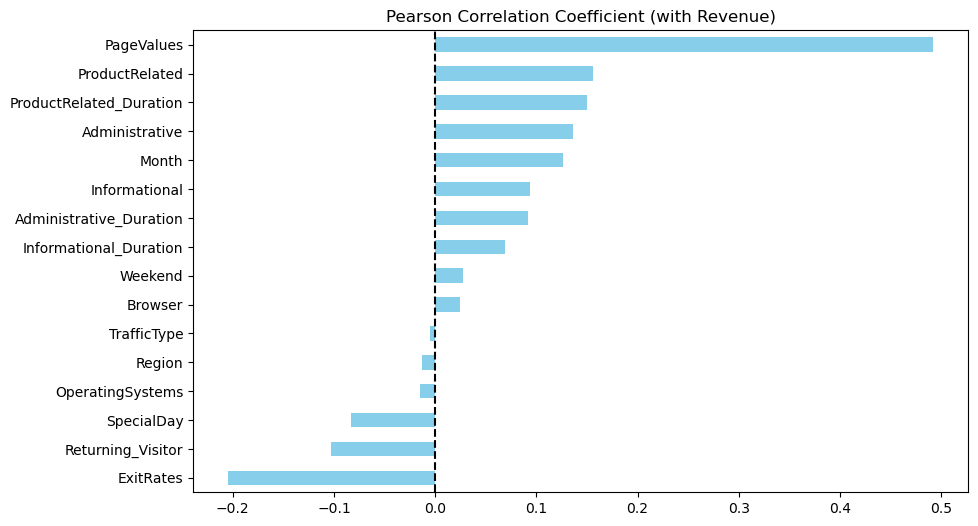

In [59]:
X_scaled_full = pd.DataFrame(scaler.transform(X), columns=X.columns)
df_viz = pd.concat([X_scaled_full, y.reset_index(drop=True)], axis=1)

corr_matrix = df_viz.corr()

revenue_corr = corr_matrix['Revenue'].drop('Revenue').sort_values()
plt.figure(figsize=(10, 6))
revenue_corr.plot(kind='barh', color='skyblue')
plt.title('Pearson Correlation Coefficient (with Revenue)')
plt.axvline(x=0, color='black', linestyle='--')
plt.show()

## 3.Data Mining

In [ ]:
import time
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

# Initialize tracking dictionaries (Compatible with Evaluation Section)
training_times = {}
prediction_times = {}
trained_models = {}

# Helper function to Tune, Track Time, and Store
def tune_and_track(name, model, params, X_train, y_train, X_test):
    print(f"\n--- Tuning {name} ---")

    # 1. Training (Grid Search)
    start_train = time.time()
    grid = GridSearchCV(model, params, cv=3, scoring='roc_auc', n_jobs=-1, verbose=1)
    grid.fit(X_train, y_train)
    end_train = time.time()

    # Store Training Time
    training_times[name] = end_train - start_train

    # 2. Prediction (for time tracking)
    best_model = grid.best_estimator_
    start_pred = time.time()
    best_model.predict(X_test)
    end_pred = time.time()

    # Store Prediction Time
    prediction_times[name] = end_pred - start_pred

    # Store Model
    trained_models[name] = best_model

    print(f"Best {name} Params: {grid.best_params_}")
    print(f"Best {name} ROC-AUC: {grid.best_score_:.4f}")
    return best_model

In [61]:
# Define Parameter Grids
lr_params = {'C': [0.1, 1, 10], 'solver': ['liblinear', 'lbfgs']}
knn_params = {'n_neighbors': [3, 5, 7], 'weights': ['uniform', 'distance']}
svc_params = {'C': [0.1, 1, 10], 'kernel': ['rbf', 'linear']}
dt_params = {'max_depth': [None, 10, 20], 'min_samples_split': [2, 5]}
rf_params = {'n_estimators': [50, 100], 'max_depth': [None, 10, 20], 'min_samples_split': [2, 5]}
gb_params = {'n_estimators': [50, 100], 'learning_rate': [0.01, 0.1], 'max_depth': [3, 5]}
nb_params = {'var_smoothing': [1e-9, 1e-8]}
mlp_params = {'hidden_layer_sizes': [(50,), (100,)], 'activation': ['relu', 'tanh'], 'alpha': [0.0001, 0.001]}

### Logistic Regression Tuning

In [62]:
tune_and_track('Logistic Regression', LogisticRegression(random_state=RANDOM_STATE, max_iter=1000), lr_params, X_train_final, y_train_balanced, X_test_final)


--- Tuning Logistic Regression ---
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best Logistic Regression Params: {'C': 10, 'solver': 'liblinear'}
Best Logistic Regression ROC-AUC: 0.9037


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",10
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multic

### K-Nearest Neighbors Tuning

In [63]:
tune_and_track('KNN', KNeighborsClassifier(), knn_params, X_train_final, y_train_balanced, X_test_final)


--- Tuning KNN ---
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best KNN Params: {'n_neighbors': 7, 'weights': 'distance'}
Best KNN ROC-AUC: 0.9360


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",7
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'distance'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


### Support Vector Classifier Tuning

In [64]:
tune_and_track('SVC', SVC(probability=True, random_state=RANDOM_STATE), svc_params, X_train_final, y_train_balanced, X_test_final)


--- Tuning SVC ---
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best SVC Params: {'C': 10, 'kernel': 'rbf'}
Best SVC ROC-AUC: 0.9174


,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",10
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


### Decision Tree Tuning

In [65]:
tune_and_track('Decision Tree', DecisionTreeClassifier(random_state=RANDOM_STATE), dt_params, X_train_final, y_train_balanced, X_test_final)


--- Tuning Decision Tree ---
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best Decision Tree Params: {'max_depth': 10, 'min_samples_split': 5}
Best Decision Tree ROC-AUC: 0.9236


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current n

### Random Forest Tuning

In [66]:
tune_and_track('Random Forest', RandomForestClassifier(random_state=RANDOM_STATE), rf_params, X_train_final, y_train_balanced, X_test_final)


--- Tuning Random Forest ---
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best Random Forest Params: {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 100}
Best Random Forest ROC-AUC: 0.9608


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

### Gradient Boosting Tuning

In [67]:
tune_and_track('Gradient Boosting', GradientBoostingClassifier(random_state=RANDOM_STATE), gb_params, X_train_final, y_train_balanced, X_test_final)


--- Tuning Gradient Boosting ---
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Gradient Boosting Params: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100}
Best Gradient Boosting ROC-AUC: 0.9567


,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are'friedman_mse' for the mean squared error with improvement score byFriedman, 'squared_error' for mean squared error. The default value of'friedman_mse' is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",5
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, 

### Gaussian Naive Bayes Tuning

In [68]:
tune_and_track('Gaussian NB', GaussianNB(), nb_params, X_train_final, y_train_balanced, X_test_final)


--- Tuning Gaussian NB ---
Fitting 3 folds for each of 2 candidates, totalling 6 fits
Best Gaussian NB Params: {'var_smoothing': 1e-08}
Best Gaussian NB ROC-AUC: 0.8435


,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-08


### MLP Classifier Tuning

In [69]:
tune_and_track('MLP Classifier', MLPClassifier(random_state=RANDOM_STATE, max_iter=1000), mlp_params, X_train_final, y_train_balanced, X_test_final)


--- Tuning MLP Classifier ---
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best MLP Classifier Params: {'activation': 'relu', 'alpha': 0.0001, 'hidden_layer_sizes': (100,)}
Best MLP Classifier ROC-AUC: 0.9425


,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(100,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",1000
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary `.",42


## 4.Evaluation

### Import Library

In [70]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix

In [71]:
eval_results = []
roc_curves = {}

### Logistic Regression Evaluation

In [72]:
name = "Logistic Regression"
model = trained_models[name]

y_pred = model.predict(X_test_final)
y_prob = model.predict_proba(X_test_final)[:, 1]

metrics = {
    'Model': name,
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1 Score': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_prob),
    'Training Time (s)': training_times[name],
    'Prediction Time (s)': prediction_times[name]
}
eval_results.append(metrics)
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_curves[name] = (fpr, tpr, metrics['ROC-AUC'])

display(pd.DataFrame([metrics]))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (s),Prediction Time (s)
0,Logistic Regression,0.868924,0.561662,0.732517,0.635812,0.884893,10.024722,0.011232


### Logistic Regression Confusion Matrix

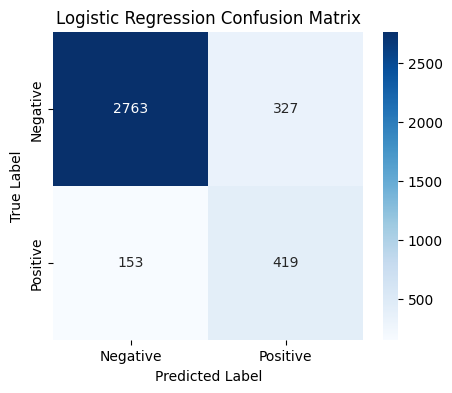

In [73]:
plt.figure(figsize=(5, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.title(f'Logistic Regression Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

### K-Nearest Neighbors Evaluation

In [74]:
name = "KNN"
model = trained_models[name]

y_pred = model.predict(X_test_final)
y_prob = model.predict_proba(X_test_final)[:, 1]

metrics = {
    'Model': name,
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1 Score': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_prob),
    'Training Time (s)': training_times[name],
    'Prediction Time (s)': prediction_times[name]
}
eval_results.append(metrics)
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_curves[name] = (fpr, tpr, metrics['ROC-AUC'])

display(pd.DataFrame([metrics]))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (s),Prediction Time (s)
0,KNN,0.840797,0.493491,0.729021,0.588567,0.871658,1.242209,0.162363


### K-Nearest Neighbors Confusion Matrix

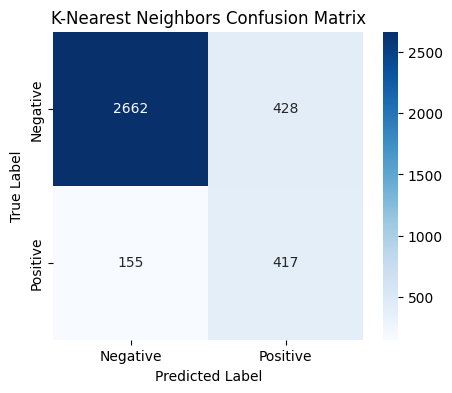

In [75]:
plt.figure(figsize=(5, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.title(f'K-Nearest Neighbors Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

### Support Vector Classifier Evaluation

In [76]:
name = "SVC"
model = trained_models[name]

y_pred = model.predict(X_test_final)
y_prob = model.predict_proba(X_test_final)[:, 1]

metrics = {
    'Model': name,
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1 Score': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_prob),
    'Training Time (s)': training_times[name],
    'Prediction Time (s)': prediction_times[name]
}
eval_results.append(metrics)
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_curves[name] = (fpr, tpr, metrics['ROC-AUC'])

display(pd.DataFrame([metrics]))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (s),Prediction Time (s)
0,SVC,0.866739,0.552764,0.769231,0.643275,0.896929,128.085288,2.759868


### Support Vector Classifier Confusion Matrix

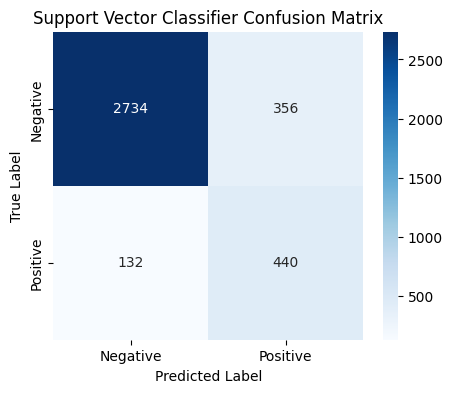

In [77]:
plt.figure(figsize=(5, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.title(f'Support Vector Classifier Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

### Decision Tree Evaluation

In [78]:
name = "Decision Tree"
model = trained_models[name]

y_pred = model.predict(X_test_final)
y_prob = model.predict_proba(X_test_final)[:, 1]

metrics = {
    'Model': name,
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1 Score': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_prob),
    'Training Time (s)': training_times[name],
    'Prediction Time (s)': prediction_times[name]
}
eval_results.append(metrics)
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_curves[name] = (fpr, tpr, metrics['ROC-AUC'])

display(pd.DataFrame([metrics]))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (s),Prediction Time (s)
0,Decision Tree,0.846259,0.504972,0.798951,0.618822,0.877254,0.447792,0.001639


### Decision Tree Confusion Matrix

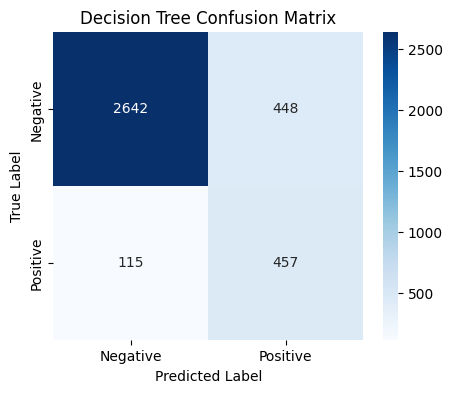

In [79]:
plt.figure(figsize=(5, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.title(f'Decision Tree Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

### Random Forest Evaluation

In [80]:
name = "Random Forest"
model = trained_models[name]

y_pred = model.predict(X_test_final)
y_prob = model.predict_proba(X_test_final)[:, 1]

metrics = {
    'Model': name,
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1 Score': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_prob),
    'Training Time (s)': training_times[name],
    'Prediction Time (s)': prediction_times[name]
}
eval_results.append(metrics)
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_curves[name] = (fpr, tpr, metrics['ROC-AUC'])

display(pd.DataFrame([metrics]))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (s),Prediction Time (s)
0,Random Forest,0.874386,0.571247,0.784965,0.661267,0.917843,11.320493,0.077717


### Random Forest Confusion Matrix

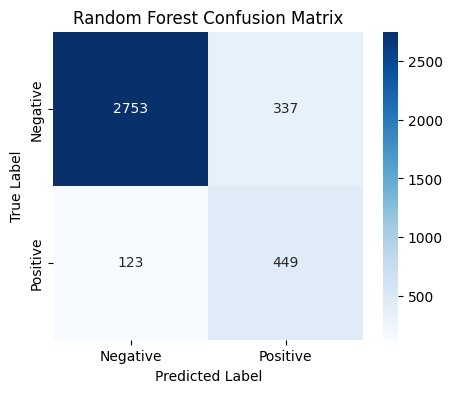

In [81]:
plt.figure(figsize=(5, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.title(f'Random Forest Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

### Gradient Boosting Classifier Evaluation

In [82]:
name = "Gradient Boosting"
model = trained_models[name]

y_pred = model.predict(X_test_final)
y_prob = model.predict_proba(X_test_final)[:, 1]

metrics = {
    'Model': name,
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1 Score': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_prob),
    'Training Time (s)': training_times[name],
    'Prediction Time (s)': prediction_times[name]
}
eval_results.append(metrics)
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_curves[name] = (fpr, tpr, metrics['ROC-AUC'])

display(pd.DataFrame([metrics]))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (s),Prediction Time (s)
0,Gradient Boosting,0.882032,0.594086,0.772727,0.671733,0.928413,12.97897,0.006434


### Gradient Boosting Classifier Confusion Matrix

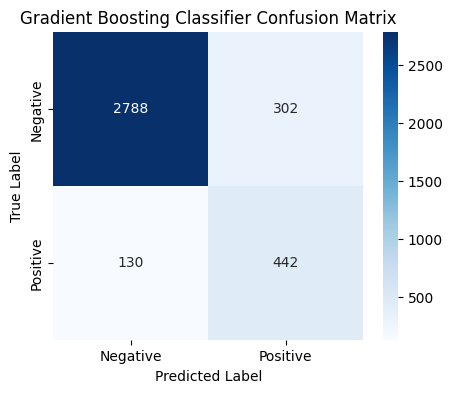

In [83]:
plt.figure(figsize=(5, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.title(f'Gradient Boosting Classifier Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

### Gaussian Naive Bayes Evaluation

In [84]:
name = "Gaussian NB"
model = trained_models[name]

y_pred = model.predict(X_test_final)
y_prob = model.predict_proba(X_test_final)[:, 1]

metrics = {
    'Model': name,
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1 Score': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_prob),
    'Training Time (s)': training_times[name],
    'Prediction Time (s)': prediction_times[name]
}
eval_results.append(metrics)
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_curves[name] = (fpr, tpr, metrics['ROC-AUC'])

display(pd.DataFrame([metrics]))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (s),Prediction Time (s)
0,Gaussian NB,0.71491,0.328239,0.788462,0.463515,0.833138,0.099994,0.0


### Gaussian Naive Bayes Confusion Matrix

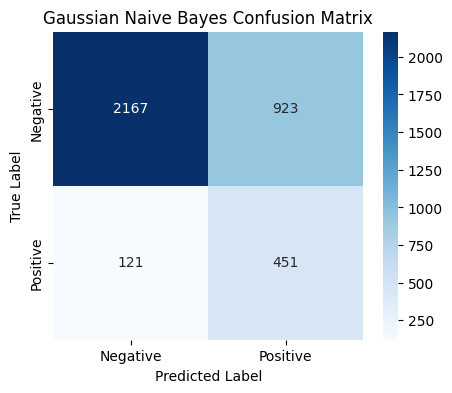

In [85]:
plt.figure(figsize=(5, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.title(f'Gaussian Naive Bayes Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

### Multilayer Perceptron Evaluation

In [86]:
name = "MLP Classifier"
model = trained_models[name]

y_pred = model.predict(X_test_final)
y_prob = model.predict_proba(X_test_final)[:, 1]

metrics = {
    'Model': name,
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1 Score': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_prob),
    'Training Time (s)': training_times[name],
    'Prediction Time (s)': prediction_times[name]
}
eval_results.append(metrics)
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_curves[name] = (fpr, tpr, metrics['ROC-AUC'])

display(pd.DataFrame([metrics]))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (s),Prediction Time (s)
0,MLP Classifier,0.874386,0.570529,0.791958,0.66325,0.925847,144.848735,0.045602


### Multilayer Perceptron Confusion Matrix

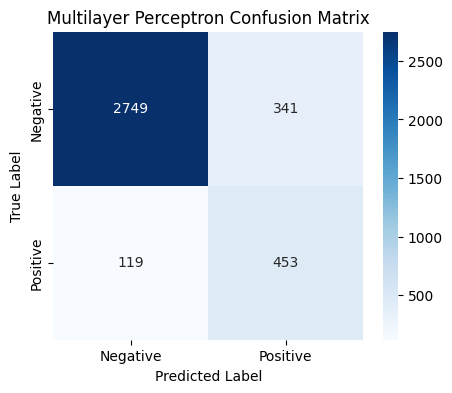

In [87]:
plt.figure(figsize=(5, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.title(f'Multilayer Perceptron Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

### Summary Table of Evaluation

In [88]:
df_results = pd.DataFrame(eval_results).sort_values(by='ROC-AUC', ascending=False)
display(df_results)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (s),Prediction Time (s)
5,Gradient Boosting,0.882032,0.594086,0.772727,0.671733,0.928413,12.978970,0.006434
7,MLP Classifier,0.874386,0.570529,0.791958,0.663250,0.925847,144.848735,0.045602
4,Random Forest,0.874386,0.571247,0.784965,0.661267,0.917843,11.320493,0.077717
2,SVC,0.866739,0.552764,0.769231,0.643275,0.896929,128.085288,2.759868
0,Logistic Regression,0.868924,0.561662,0.732517,0.635812,0.884893,10.024722,0.011232
3,Decision Tree,0.846259,0.504972,0.798951,0.618822,0.877254,0.447792,0.001639
1,KNN,0.840797,0.493491,0.729021,0.588567,0.871658,1.242209,0.162363
6,Gaussian NB,0.714910,0.328239,0.788462,0.463515,0.833138,0.099994,0.000000


### Model Performance Metrics Comparison

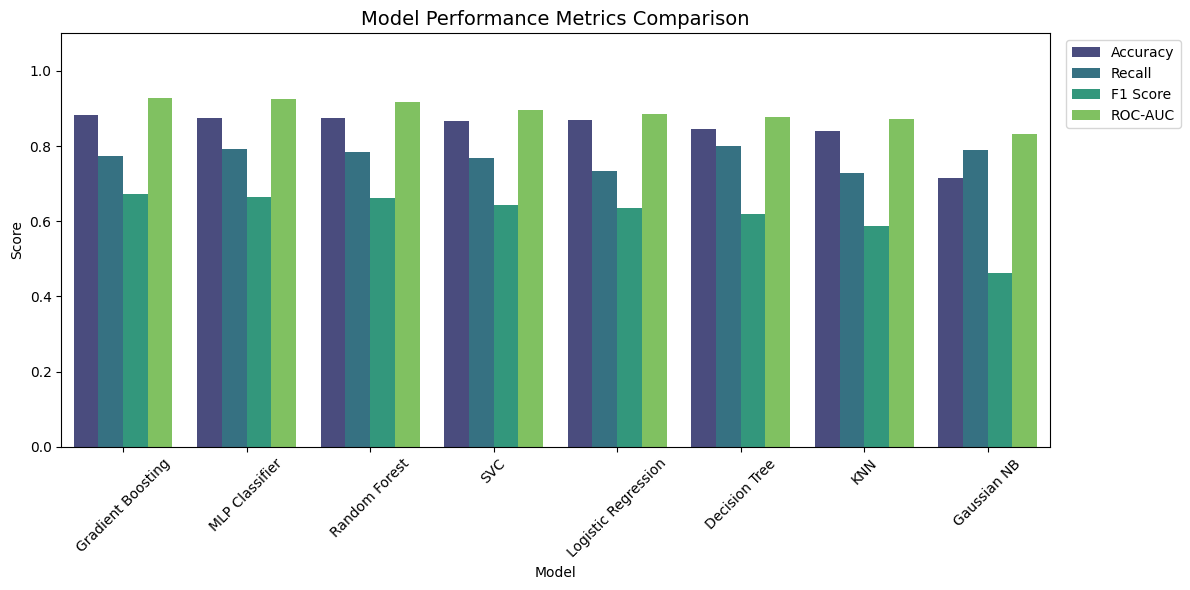

In [89]:
metrics_to_plot = ['Accuracy', 'Recall', 'F1 Score', 'ROC-AUC']
df_long = df_results.melt(id_vars='Model', value_vars=metrics_to_plot,
                          var_name='Metric', value_name='Score')

plt.figure(figsize=(12, 6))
sns.barplot(data=df_long, x='Model', y='Score', hue='Metric', palette='viridis')
plt.title('Model Performance Metrics Comparison', fontsize=14)
plt.ylabel('Score')
plt.ylim(0.0, 1.1)
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Time Comparison

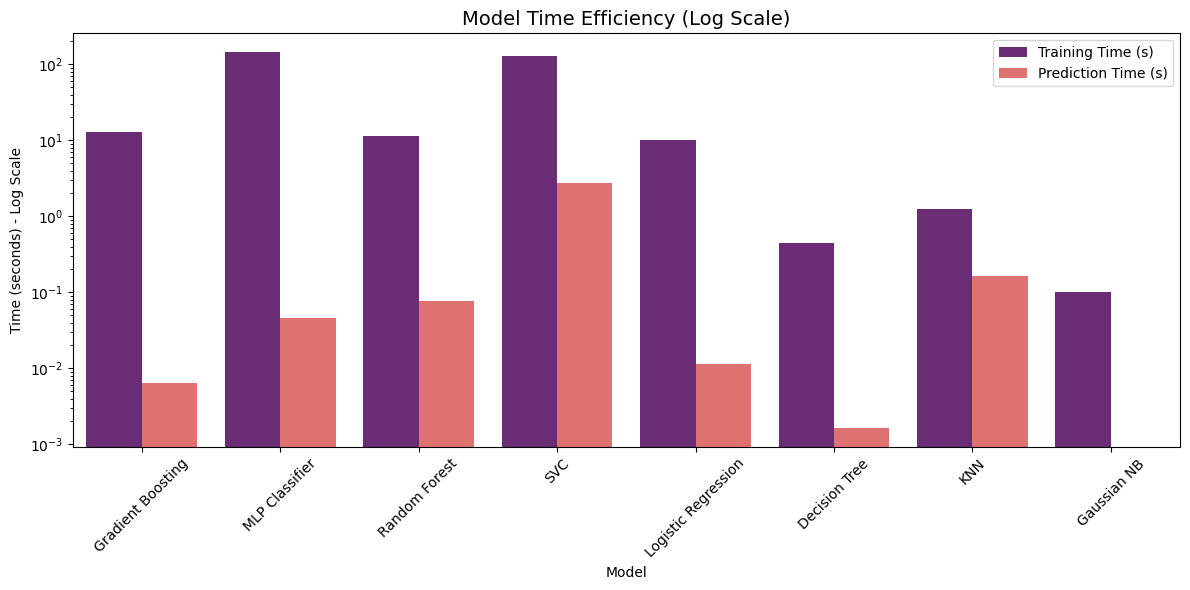

In [90]:
time_df = df_results[['Model', 'Training Time (s)', 'Prediction Time (s)']]
time_long = time_df.melt(id_vars='Model', var_name='Time Type', value_name='Time (s)')

plt.figure(figsize=(12, 6))
sns.barplot(data=time_long, x='Model', y='Time (s)', hue='Time Type', palette='magma')
plt.title('Model Time Efficiency (Log Scale)', fontsize=14)
plt.ylabel('Time (seconds) - Log Scale')
plt.yscale('log')
plt.xticks(rotation=45)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

### ROC Curves

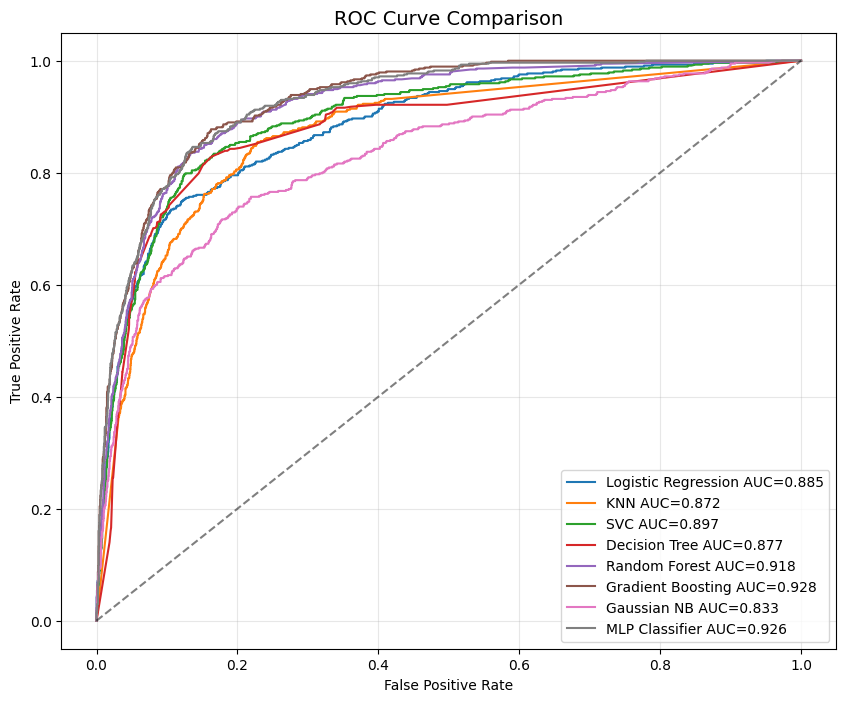

In [92]:
plt.figure(figsize=(10, 8))
for name, (fpr, tpr, auc) in roc_curves.items():
    plt.plot(fpr, tpr, label=f'{name} AUC={auc:.3f}')

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison', fontsize=14)
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()